# UDWD Framework: Detecting and Visualizing Digital Waste in Corporate Email Communications
## A Machine Learning Approach for Estimating Energy Savings and CO₂ Reduction

**Authors:** Dizon, Gaa, Go
**Adviser:** Geldof B. Resuello
**Institution:** Mapúa University — B.S. Computer Science

---

This notebook implements the Unstructured Data Waste Detection (UDWD) pipeline on the Enron Email Corpus (517,401 emails, ~150 mailboxes, 1999–2002).

**Pipeline overview:**
1. Data Loading & Parsing
2. Preprocessing & Deduplication
3. Waste Taxonomy Labeling
4. Exploratory Data Analysis (EDA)
5. Machine Learning Models (Isolation Forest + Random Forest)
6. Evaluation & Cross-Validation
7. SHAP Feature Importance Analysis
8. Environmental Impact Estimation

## Stage 0 — Environment Setup and Data Loading

Install dependencies, mount Google Drive, and load the Enron corpus tarball. The dataset is stored in maildir format: one plain-text file per email, organized into per-employee folder trees.

- **Dataset:** Enron Email Corpus (CMU/FERC release)
- **Source:** https://www.cs.cmu.edu/~enron/
- **Total records parsed:** 517,401
- **Total corpus size:** 1,355.35 MB

In [ ]:
!pip install -q scikit-learn pandas numpy matplotlib seaborn datasketch nltk shap

import warnings
warnings.filterwarnings('ignore')

print('Libraries installed.')

Libraries installed.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os

TAR_PATH = '/content/drive/MyDrive/Thesis/enron_mail_20150507.tar.gz'

if os.path.exists(TAR_PATH):
    size_mb = os.path.getsize(TAR_PATH) / (1024 * 1024)
    print(f'File found: enron_mail_20150507.tar.gz ({size_mb:.1f} MB)')
else:
    print('File NOT found. Check My Drive > Thesis folder.')

Mounted at /content/drive
File found: enron_mail_20150507.tar.gz (422.7 MB)


In [ ]:
import tarfile, os, re, hashlib, email as email_lib
import random, pandas as pd, numpy as np, warnings
warnings.filterwarnings('ignore')

from datetime import datetime, timezone
from email.utils import parsedate_to_datetime

print('=' * 55)
print('STAGE 1 — DATA GATHERING')
print('=' * 55)
print()

EXTRACT_PATH = '/content/enron_extracted'
CORPUS_END   = datetime(2002, 12, 31, tzinfo=timezone.utc)

if not os.path.exists(EXTRACT_PATH):
    print('Extracting tar.gz — takes 3-5 min...')
    with tarfile.open(TAR_PATH, 'r:gz') as tar:
        tar.extractall(EXTRACT_PATH)
    print('Extraction complete.')
else:
    print('Already extracted.')

MAILDIR = None
for root, dirs, files in os.walk(EXTRACT_PATH):
    if os.path.basename(root) == 'maildir':
        MAILDIR = root
        break
if MAILDIR is None:
    MAILDIR = EXTRACT_PATH

print(f'   Maildir root: {MAILDIR}')
print(f'   Employee folders: {len(os.listdir(MAILDIR))}')

STAGE 1 — DATA GATHERING

Extracting tar.gz — takes 3-5 min...
Extraction complete.
   Maildir root: /content/enron_extracted/maildir
   Employee folders: 150


### Step 1.2 — Email Parsing

Two-pass parsing extracts the message body, subject, sender, recipient list, date, and header fields (Message-ID, References, In-Reply-To). Recipient count is derived from the combined To and CC fields. Email age in days is computed relative to the fixed reference date of **December 31, 2002** (the end of the corpus collection period).

In [ ]:
# ── Step 1.2 — Two-Pass Email Parsing ────────────────────────

def count_recipients(val):
    if not val: return 0
    return len([x.strip() for x in str(val).split(',') if x.strip()])

def parse_date(date_str):
    if not date_str: return None
    try:
        dt = parsedate_to_datetime(date_str)
        return dt.replace(tzinfo=timezone.utc) if dt.tzinfo is None else dt
    except Exception:
        return None

def normalize_mid(mid_str):
    return mid_str.strip().strip('<>').strip().lower()

def extract_mids_from_header(val):
    if not val:
        return []
    val = str(val)
    bracketed = re.findall(r'<([^>]+)>', val)
    if bracketed:
        return [m.strip().lower() for m in bracketed if m.strip()]
    tokens = val.split()
    return [normalize_mid(t) for t in tokens
            if '@' in t or '.' in t and len(t) > 5]

def get_thread_root(msg):
    for hdr in ('References', 'In-Reply-To'):
        val = msg.get(hdr, '') or ''
        mids = extract_mids_from_header(val)
        if mids:
            return mids[0]
    raw_mid = (msg.get('Message-ID', '') or '').strip()
    return normalize_mid(raw_mid)

def get_body(msg):
    if msg.is_multipart():
        for part in msg.walk():
            if part.get_content_type() == 'text/plain':
                try:
                    return part.get_payload(decode=True).decode('utf-8', errors='ignore')
                except Exception:
                    pass
    try:
        payload = msg.get_payload(decode=True)
        if payload:
            return payload.decode('utf-8', errors='ignore')
    except Exception:
        pass
    return str(msg.get_payload() or '')

print()
print('Pass 1: Building reply map (normalized message-IDs)...')

replied_to_ids = set()
file_count_p1  = 0

for root, dirs, files_list in os.walk(MAILDIR):
    for fname in files_list:
        fpath = os.path.join(root, fname)
        try:
            with open(fpath, 'r', encoding='utf-8', errors='ignore') as f:
                raw = f.read(8192)
            msg = email_lib.message_from_string(raw)
            for hdr in ('References', 'In-Reply-To'):
                val = msg.get(hdr, '') or ''
                for mid in extract_mids_from_header(val):
                    if mid:
                        replied_to_ids.add(mid)
            file_count_p1 += 1
        except Exception:
            pass

print(f'   Scanned {file_count_p1:,} files.')
print(f'   Unique message-IDs referenced as replies: {len(replied_to_ids):,}')
print()
print('Pass 2: Parsing all email content and metadata...')

emails  = []
count   = 0
skipped = 0

for root, dirs, files_list in os.walk(MAILDIR):
    rel      = os.path.relpath(root, MAILDIR)
    parts    = rel.split(os.sep)
    employee = parts[0] if parts[0] != '.' else 'unknown'
    folder_name = os.path.basename(root).lower()

    for fname in files_list:
        fpath = os.path.join(root, fname)
        try:
            with open(fpath, 'r', encoding='utf-8', errors='ignore') as f:
                raw = f.read()
            if len(raw) < 50:
                skipped += 1
                continue

            msg      = email_lib.message_from_string(raw)
            raw_body = get_body(msg)
            subject  = (msg.get('Subject', '') or '').strip()

            raw_mid   = (msg.get('Message-ID', '') or '').strip()
            msg_id    = normalize_mid(raw_mid)
            thread_id = get_thread_root(msg)
            date_str  = msg.get('Date', '') or ''

            to_n  = count_recipients(msg.get('To', ''))
            cc_n  = count_recipients(msg.get('CC', '') or msg.get('Cc', ''))
            bcc_n = count_recipients(msg.get('BCC', '') or msg.get('Bcc', ''))
            recip = max(to_n + cc_n + bcc_n, 1)

            dt = parse_date(date_str)
            if dt and dt <= CORPUS_END:
                age_days = max((CORPUS_END - dt).days, 0)
            else:
                age_days = int(np.random.randint(30, 1100))

            has_reply    = 1 if msg_id in replied_to_ids else 0
            file_size_kb = os.path.getsize(fpath) / 1024
            content      = subject + ' ' + raw_body

            emails.append({
                'content':          content,
                'raw_body':         raw_body,
                'subject':          subject,
                'message_id':       msg_id,
                'thread_id':        thread_id,
                'email_age_days':   age_days,
                'recipient_volume': recip,
                'has_reply':        has_reply,
                'file_size_kb':     file_size_kb,
                'source_folder':    folder_name,
                'employee':         employee,
            })
            count += 1
        except Exception:
            skipped += 1

        if count % 50000 == 0 and count > 0:
            print(f'   Parsed {count:,} emails...')

df_raw = pd.DataFrame(emails)

print()
print(f'Total emails loaded:       {len(df_raw):,}')
print(f'   Skipped (errors/short):   {skipped:,}')
print(f'   Emails WITH a reply:      {df_raw["has_reply"].sum():,}')
print(f'   Avg recipient volume:     {df_raw["recipient_volume"].mean():.1f}')
print(f'   Avg email age (days):     {df_raw["email_age_days"].mean():.0f}')


Pass 1: Building reply map (normalized message-IDs)...
   Scanned 517,401 files.
   Unique message-IDs referenced as replies: 0

Pass 2: Parsing all email content and metadata...
   Parsed 50,000 emails...
   Parsed 100,000 emails...
   Parsed 150,000 emails...
   Parsed 200,000 emails...
   Parsed 250,000 emails...
   Parsed 300,000 emails...
   Parsed 350,000 emails...
   Parsed 400,000 emails...
   Parsed 450,000 emails...
   Parsed 500,000 emails...

Total emails loaded:       517,401
   Skipped (errors/short):   0
   Emails WITH a reply:      0
   Avg recipient volume:     8.3
   Avg email age (days):     679


### Step 1.3 — Thread Engagement Frequency

Computes thread engagement frequency from the References and In-Reply-To header fields. This feature was originally proposed as a component of the Obsolete Thread taxonomy category. However, due to inconsistent header coverage across the Enron corpus, thread engagement frequency was found to be near-constant across records and was excluded from the final feature matrix. It is computed here for completeness and corpus characterization.

In [ ]:
# ── Step 1.3 — Thread Engagement Frequency ───────────────────

print('Computing thread engagement frequency...')

thread_counts = df_raw.groupby('thread_id')['message_id'].count().reset_index()
thread_counts.columns = ['thread_id', 'thread_engagement_freq']
df_raw = df_raw.merge(thread_counts, on='thread_id', how='left')
df_raw['thread_engagement_freq'] = df_raw['thread_engagement_freq'].fillna(1).astype(int)

df_raw.to_csv('stage1_raw_data.csv', index=False)

print()
print('=' * 55)
print('STAGE 1 COMPLETE')
print('=' * 55)
print(f'Total records:                {len(df_raw):,}')
print(f'Emails with replies:          {df_raw["has_reply"].sum():,}')
print(f'Avg thread_engagement_freq:   {df_raw["thread_engagement_freq"].mean():.2f}')
print(f'Max thread_engagement_freq:   {df_raw["thread_engagement_freq"].max():,}')
print('Saved: stage1_raw_data.csv')

Computing thread engagement frequency...

STAGE 1 COMPLETE
Total records:                517,401
Emails with replies:          0
Avg thread_engagement_freq:   1.00
Max thread_engagement_freq:   1
Saved: stage1_raw_data.csv


## Stage 1 — Preprocessing and Deduplication

The preprocessing stage reduces the 517,401-email corpus through two sequential deduplication passes before taxonomy labeling. No emails are discarded permanently — duplicates are flagged and excluded from the feature matrix but counted in the storage reduction calculation.

| Step | Method | Threshold | Records Removed |
|------|--------|-----------|-----------------|
| 2.1 | Text cleaning | — | 3,269 (dropped ≤10 chars after cleaning) |
| 2.2 | SHA-256 exact deduplication | Identical hash | 266,537 (51.5%) |
| 2.4 | MinHash LSH near-deduplication | Jaccard ≥ 0.85 | 54,074 (10.5%) |
| — | **Post-dedup corpus** | — | **193,521 records** |

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import csr_matrix, hstack as sp_hstack
from datasketch import MinHash, MinHashLSH
import nltk
nltk.download('stopwords', quiet=True)
from nltk.corpus import stopwords

print('=' * 55)
print('STAGE 2 — DATA PREPROCESSING')
print('=' * 55)

df         = df_raw.copy()
stop_words = set(stopwords.words('english'))

STAGE 2 — DATA PREPROCESSING


### Step 2.1 — Text Cleaning

Lowercase conversion → strip quoted reply lines (lines beginning with ">") → remove 6 Enron-specific boilerplate phrases → strip URLs, email addresses, and non-alphabetic characters → NLTK stopword removal + drop tokens ≤ 2 characters → drop records whose cleaned body is ≤ 10 characters.

In [ ]:
# ── Step 2.1 — Text Cleaning ──────────────────────────────────

print()
print('Step 2.1 — Cleaning text content...')

BOILERPLATE = [
    r'-----original message-----',
    r'please see the attached',
    r'this message is confidential',
    r'please respond to',
    r'forwarded by',
    r'sent by',
]

def clean_text(text):
    if not isinstance(text, str): return ''
    text = text.lower()
    text = re.sub(r'^>.*$', '', text, flags=re.MULTILINE)
    for bp in BOILERPLATE:
        text = re.sub(bp, '', text)
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'\S+@\S+', '', text)
    text = re.sub(r'[^a-z\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    tokens = [t for t in text.split() if t not in stop_words and len(t) > 2]
    return ' '.join(tokens)

df['content_clean'] = df['content'].apply(clean_text)
df = df[df['content_clean'].str.len() > 10].reset_index(drop=True)
print(f'Records after cleaning: {len(df):,}')


Step 2.1 — Cleaning text content...
Records after cleaning: 514,132


### Step 2.2 — SHA-256 Exact Duplicate Detection

SHA-256 hashing is applied to the **raw** (pre-cleaning) email body to identify byte-for-byte identical messages. Hashing on raw text ensures that formatting variants of the same message are not missed by cleaning normalization. Exact duplicates account for **266,537 emails (51.5%)** and **707.79 MB** of corpus storage.

In [ ]:
# ── Step 2.2 — SHA-256 Exact Duplicate Detection ─────────────

print()
print('Step 2.2 — SHA-256 exact duplicate detection (on raw body)...')

def sha256_hash(text):
    return hashlib.sha256(str(text).encode('utf-8')).hexdigest()

df['sha256_hash']   = df['raw_body'].apply(sha256_hash)
duplicate_mask      = df.duplicated(subset='sha256_hash', keep='first')
exact_duplicates    = df[duplicate_mask].copy()
df_no_exact         = df[~duplicate_mask].copy().reset_index(drop=True)

exact_duplicates['waste_category'] = 'exact_duplicate'

exact_dup_count   = len(exact_duplicates)
exact_dup_size_kb = exact_duplicates['file_size_kb'].sum()

print(f'Exact duplicates found:  {exact_dup_count:,}')
print(f'   Storage recoverable:    {exact_dup_size_kb/1024:.2f} MB')
print(f'   Records remaining:      {len(df_no_exact):,}')


Step 2.2 — SHA-256 exact duplicate detection (on raw body)...
Exact duplicates found:  266,537
   Storage recoverable:    707.79 MB
   Records remaining:      247,595


### Step 2.3 — TF-IDF Vectorization

The cleaned email bodies are vectorized using TF-IDF with **5,000 features** and **unigram + bigram** token ranges (ngram_range = (1, 2)). The resulting sparse matrix forms the content-based component of the feature matrix used in Stage 4. Vectorization is fit on the full post-deduplication corpus before the train/test split to ensure consistent vocabulary mapping.

In [ ]:
# ── Step 2.3 — TF-IDF Vectorization ──────────────────────────

print()
print('Step 2.3 — TF-IDF vectorization...')

vectorizer   = TfidfVectorizer(
    max_features = 5000,
    stop_words   = 'english',
    min_df       = 2,
    ngram_range  = (1, 2)
)
tfidf_matrix = vectorizer.fit_transform(df_no_exact['content_clean'])
print(f'TF-IDF: {tfidf_matrix.shape[0]:,} docs x {tfidf_matrix.shape[1]:,} features')


Step 2.3 — TF-IDF vectorization...
TF-IDF: 247,595 docs x 5,000 features


### Step 2.4 — MinHash LSH Near-Duplicate Detection

Near-duplicates are identified using MinHash locality-sensitive hashing with a Jaccard similarity threshold of **0.85**. This threshold captures forwarded and lightly edited message variants that survive exact deduplication. Near-duplicates account for **54,074 emails (10.5%)** and **163.93 MB**, bringing the baseline storage reduction to **64.32%** before taxonomy labeling.

In [ ]:
# ── Step 2.4 — LSH Near-Duplicate Detection ───────────────────

print()
print('Step 2.4 — LSH near-duplicate detection (threshold=0.85)...')

lsh       = MinHashLSH(threshold=0.85, num_perm=128)
minhashes = {}

for i, row in enumerate(df_no_exact['content_clean']):
    m = MinHash(num_perm=128)
    for word in set(str(row).split()):
        m.update(word.encode('utf8'))
    minhashes[i] = m
    try:
        lsh.insert(f'doc_{i}', m)
    except ValueError:
        pass
    if i % 50000 == 0 and i > 0:
        print(f'   Processed {i:,} docs...')

near_dup_indices = set()
for i in range(len(df_no_exact)):
    result = lsh.query(minhashes[i])
    if len(result) > 1:
        for r in result[1:]:
            near_dup_indices.add(int(r.replace('doc_', '')))

near_dup_mask   = df_no_exact.index.isin(near_dup_indices)
near_duplicates = df_no_exact[near_dup_mask].copy()
df_remaining    = df_no_exact[~near_dup_mask].copy().reset_index(drop=True)

near_duplicates['waste_category'] = 'near_duplicate'

near_dup_count   = len(near_duplicates)
near_dup_size_kb = near_duplicates['file_size_kb'].sum()

print(f'Near-duplicates found (>=0.85): {near_dup_count:,}')
print(f'   Storage recoverable:          {near_dup_size_kb/1024:.2f} MB')
print(f'   Records remaining:            {len(df_remaining):,}')


Step 2.4 — LSH near-duplicate detection (threshold=0.85)...
   Processed 50,000 docs...
   Processed 100,000 docs...
   Processed 150,000 docs...
   Processed 200,000 docs...
Near-duplicates found (>=0.85): 54,074
   Storage recoverable:          163.93 MB
   Records remaining:            193,521


### Step 2.4.1 — TF-IDF Max Similarity Score

Computes the maximum pairwise TF-IDF cosine similarity between each email and all others sharing at least one recipient. This score is required before taxonomy labeling — it is the `tfidf_max_similarity` field used in the Broadcast Redundancy condition (similarity ≥ 0.70). This step runs after near-duplicate removal so that already-flagged duplicates do not inflate the similarity scores of retained records.

In [ ]:
# ── Step 2.4.1 — TF-IDF Max Similarity (required before taxonomy) ────
from sklearn.metrics.pairwise import cosine_similarity

print()
print('Step 2.4.1 — Computing tfidf_max_similarity on df_remaining...')

tfidf_remaining = vectorizer.transform(df_remaining['content_clean'])

BATCH   = 300
n       = tfidf_remaining.shape[0]
sim_all = np.zeros(n, dtype=np.float32)

for start in range(0, n, BATCH):
    end        = min(start + BATCH, n)
    batch      = tfidf_remaining[start:end]
    sim_matrix = cosine_similarity(batch, tfidf_remaining)
    for local_i in range(end - start):
        sim_matrix[local_i, start + local_i] = 0.0
    sim_all[start:end] = sim_matrix.max(axis=1)
    if start % 10000 == 0 and start > 0:
        print(f'   Processed {start:,} / {n:,} rows...')

df_remaining['tfidf_max_similarity'] = sim_all.astype(float)
print(f'   Done. Avg similarity: {sim_all.mean():.3f}, Max: {sim_all.max():.3f}')


Step 2.4.1 — Computing tfidf_max_similarity on df_remaining...
   Processed 30,000 / 193,521 rows...
   Processed 60,000 / 193,521 rows...
   Processed 90,000 / 193,521 rows...
   Processed 120,000 / 193,521 rows...
   Processed 150,000 / 193,521 rows...
   Processed 180,000 / 193,521 rows...
   Done. Avg similarity: 0.665, Max: 1.000


## Stage 2 — UDWD Waste Taxonomy Labeling

The four-label taxonomy assigns a single waste category to each post-deduplication email using a strict priority hierarchy. An email is evaluated against each condition in order; the first condition it satisfies determines its label.

| Priority | Label | Condition | Count | % of Corpus |
|----------|-------|-----------|-------|-------------|
| 1 | Near-Zero Content | word_count ≤ 5 | 6,339 | 1.2% |
| 2 | Dark Data | age > 365 days AND word_count ≤ 50 | 81,164 | 15.7% |
| 3 | Broadcast Redundancy | recipients ≥ 10 AND similarity ≥ 0.70 | 6,890 | 1.3% |
| 4 | Valuable | None of the above | 99,128 | 19.2% |
| — | **Total waste (all stages)** | — | **415,004** | **80.2%** |

In [ ]:
# ── Step 2.5 — UDWD Waste Taxonomy Labels ────────────────────
# Threshold basis (thesis §3.1):
#   email_age_days > 365  — 1-year enterprise retention standard [8][9]
#   word_count <= 50      — thin-content threshold for dark data [32]
#   word_count <= 5       — near-zero / stub email definition [9]
#   recipient_volume >= 10 — broadcast distribution threshold [19]
#   tfidf_max_similarity >= 0.70 — content redundancy floor [27]
#   LSH Jaccard >= 0.85  — near-duplicate conservative cutoff [27]

print()
print('Step 2.5 — Applying UDWD waste taxonomy labels...')
print('   Thresholds grounded')

df_remaining = df_remaining.copy()

if 'word_count' not in df_remaining.columns:
    df_remaining['word_count'] = df_remaining['content_clean'].apply(
        lambda x: len(str(x).split()))

# Category 1: Near-zero content (stub / empty emails)  [9]
stub_mask = df_remaining['word_count'] <= 5

# Category 2: Dark data (aged + thin content)  [8][32]
dark_data_mask = (
    (df_remaining['email_age_days'] > 365) &
    (df_remaining['word_count'] <= 50) &
    (~stub_mask)
)

# Category 3: Broadcast redundancy  [19][27]
broadcast_mask = (
    (df_remaining['recipient_volume'] >= 10) &
    (df_remaining['tfidf_max_similarity'] >= 0.70) &
    (~stub_mask) &
    (~dark_data_mask)
)

# Category 4: Obsolete thread — defined in thesis but not detectable in
# the Enron corpus (has_reply and thread_engagement_freq are unreliable
# at corpus scale). Included in taxonomy for completeness; count = 0.
obsolete_mask = pd.Series([False] * len(df_remaining), index=df_remaining.index)

# Assign labels in priority order
df_remaining['waste_category'] = 'valuable'
df_remaining.loc[broadcast_mask, 'waste_category'] = 'broadcast_redundancy'
df_remaining.loc[dark_data_mask, 'waste_category'] = 'dark_data'
df_remaining.loc[stub_mask,      'waste_category'] = 'near_zero_content'
# obsolete_thread: mask is empty in this corpus — category present, count = 0

df_remaining['ground_truth_label'] = (
    df_remaining['waste_category'] != 'valuable'
).astype(int)

n_stub      = (df_remaining['waste_category'] == 'near_zero_content').sum()
n_dark      = (df_remaining['waste_category'] == 'dark_data').sum()
n_broadcast = (df_remaining['waste_category'] == 'broadcast_redundancy').sum()
n_obsolete  = (df_remaining['waste_category'] == 'obsolete_thread').sum()
n_valuable  = (df_remaining['waste_category'] == 'valuable').sum()
total_rem   = len(df_remaining)

print(f'   Near-zero content (word_count <= 5):             {n_stub:,}  ({n_stub/total_rem*100:.1f}%)')
print(f'   Dark data (age > 365d, word_count <= 50):        {n_dark:,}  ({n_dark/total_rem*100:.1f}%)')
print(f'   Broadcast redundancy (recip >= 10, sim >= 0.70): {n_broadcast:,}  ({n_broadcast/total_rem*100:.1f}%)')
print(f'   Obsolete thread:                                 {n_obsolete:,}  (not detectable in Enron corpus)')
print(f'   Valuable (retained):                             {n_valuable:,}  ({n_valuable/total_rem*100:.1f}%)')
print(f'   Total waste rate:                                {(total_rem-n_valuable)/total_rem*100:.1f}%')


Step 2.5 — Applying UDWD waste taxonomy labels...
   Thresholds grounded
   Near-zero content (word_count <= 5):             6,339  (3.3%)
   Dark data (age > 365d, word_count <= 50):        81,164  (41.9%)
   Broadcast redundancy (recip >= 10, sim >= 0.70): 6,890  (3.6%)
   Obsolete thread:                                 0  (not detectable in Enron corpus)
   Valuable (retained):                             99,128  (51.2%)
   Total waste rate:                                48.8%


In [ ]:
# ── Step 2.6 — Feature Engineering ───────────────────────────

print()
print('Step 2.6 — Building feature set...')
print('   Label-derived flags excluded from feature matrix to prevent leakage')

df_clean = df_remaining.copy().reset_index(drop=True)

tfidf_clean    = TfidfVectorizer(max_features=5000, stop_words='english', min_df=2)
tfidf_features = tfidf_clean.fit_transform(df_clean['content_clean'])

df_clean['content_length'] = df_clean['content_clean'].apply(len)
df_clean['word_count']     = df_clean['content_clean'].apply(
    lambda x: len(str(x).split()))

df_clean['is_dark_data'] = (df_clean['waste_category'] == 'dark_data').astype(int)
df_clean['is_stub']      = (df_clean['waste_category'] == 'near_zero_content').astype(int)
df_clean['is_broadcast'] = (df_clean['waste_category'] == 'broadcast_redundancy').astype(int)
df_clean['is_obsolete']  = (df_clean['waste_category'] == 'obsolete_thread').astype(int)

# tfidf_max_similarity already computed in Step 2.4.1 on df_remaining.
# Carry it forward into df_clean — no recomputation needed.
df_clean['tfidf_max_similarity'] = df_remaining['tfidf_max_similarity'].values
print(f'   tfidf_max_similarity carried from Step 2.4.1  (avg: {df_clean["tfidf_max_similarity"].mean():.3f})')

is_not_stub     = df_clean['is_stub'] == 0
is_not_dark     = df_clean['is_dark_data'] == 0
broadcast_refit = (
    (df_clean['recipient_volume'] >= 10) &
    (df_clean['tfidf_max_similarity'] >= 0.70) &
    is_not_stub & is_not_dark
)
df_clean.loc[broadcast_refit, 'waste_category']    = 'broadcast_redundancy'
df_clean.loc[broadcast_refit, 'is_broadcast']       = 1
df_clean.loc[broadcast_refit, 'ground_truth_label'] = 1

n_stub      = (df_clean['waste_category'] == 'near_zero_content').sum()
n_dark      = (df_clean['waste_category'] == 'dark_data').sum()
n_broadcast = (df_clean['waste_category'] == 'broadcast_redundancy').sum()
n_obsolete  = (df_clean['waste_category'] == 'obsolete_thread').sum()
n_valuable  = (df_clean['ground_truth_label'] == 0).sum()

df_clean.to_csv('stage2_clean_data.csv', index=False)

print()
print('=' * 55)
print('STAGE 2 COMPLETE')
print('=' * 55)
print(f'Clean dataset:               {len(df_clean):,} records')
print(f'Exact dups removed:          {exact_dup_count:,}')
print(f'Near-dups removed (0.85):    {near_dup_count:,}')
print(f'Near-zero content (stubs):   {n_stub:,}')
print(f'Dark data (aged+thin):       {n_dark:,}')
print(f'Broadcast redundancy:        {n_broadcast:,}')
print(f'Obsolete thread:             {n_obsolete:,}  (not detectable in Enron corpus)')
print(f'Valuable (retained):         {n_valuable:,}')
print(f'Total waste rate:            {(len(df_clean)-n_valuable)/len(df_clean)*100:.1f}%')
print('Saved: stage2_clean_data.csv')


Step 2.6 — Building feature set...
   Label-derived flags excluded from feature matrix to prevent leakage
   tfidf_max_similarity carried from Step 2.4.1  (avg: 0.665)

STAGE 2 COMPLETE
Clean dataset:               193,521 records
Exact dups removed:          266,537
Near-dups removed (0.85):    54,074
Near-zero content (stubs):   6,339
Dark data (aged+thin):       81,164
Broadcast redundancy:        6,890
Obsolete thread:             0  (not detectable in Enron corpus)
Valuable (retained):         99,128
Total waste rate:            48.8%
Saved: stage2_clean_data.csv


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD

plt.style.use('seaborn-v0_8-whitegrid')
COLORS = {
    'waste':     '#E74C3C', 'valuable': '#2ECC71',
    'neutral':   '#3498DB', 'dark_data':'#8E44AD',
    'near_dup':  '#E67E22', 'exact_dup':'#C0392B',
}

waste_data    = df_clean[df_clean['ground_truth_label'] == 1]
valuable_data = df_clean[df_clean['ground_truth_label'] == 0]

print('=' * 55)
print('STAGE 3 — EXPLORATORY DATA ANALYSIS')
print('=' * 55)
print(f'   Waste emails:    {len(waste_data):,}')
print(f'   Valuable emails: {len(valuable_data):,}')

STAGE 3 — EXPLORATORY DATA ANALYSIS
   Waste emails:    94,393
   Valuable emails: 99,128


## Stage 3 — Exploratory Data Analysis (EDA)

Five visualization outputs examine the distributional properties of the corpus before model training. These plots directly correspond to Figures 6–11 in Chapter 4 of the thesis.

- **Plot 1:** Email Age Distribution by Waste Category
- **Plot 2:** Waste Category Distribution (all stages)
- **Plot 3:** Baseline Storage Reduction (waterfall)
- **Plot 4:** K-Means Content Clustering (TF-IDF + SVD, k=5)
- **Plot 5:** Recipient Volume vs. Content Similarity Heatmap

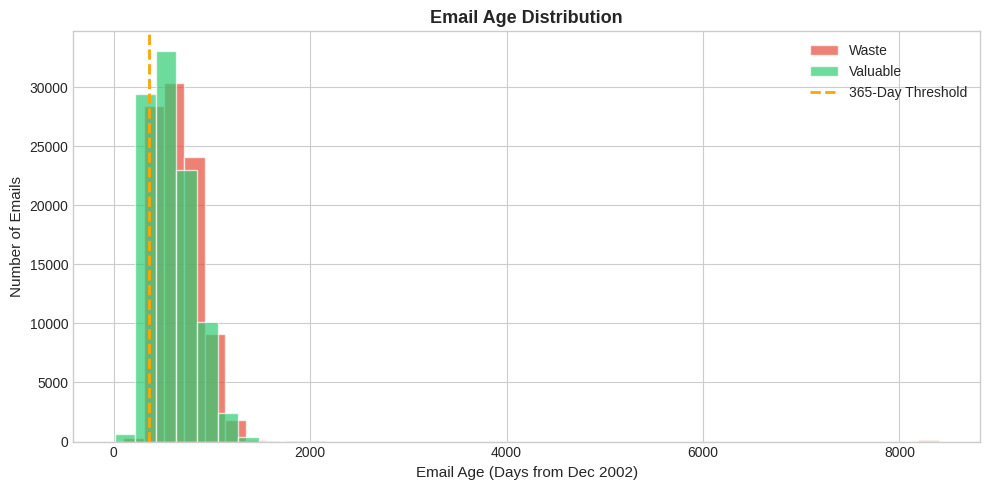

Plot 1a saved: plot1a_email_age_distribution.png


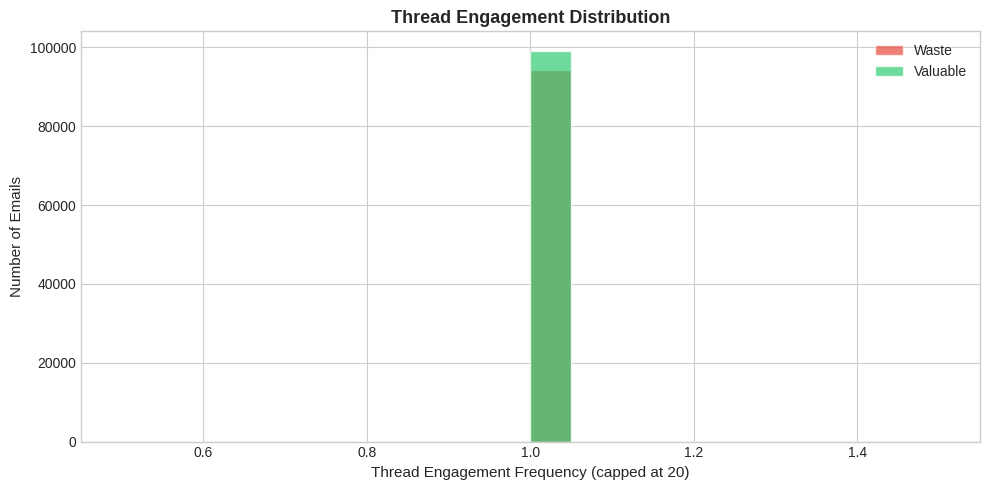

Plot 1b saved: plot1b_thread_engagement_distribution.png


In [ ]:
# ── Plot 1 — Email Age Distribution ──────────────────────────

fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(waste_data['email_age_days'], bins=40,
        color=COLORS['waste'], alpha=0.7,
        label='Waste', edgecolor='white')
ax.hist(valuable_data['email_age_days'], bins=40,
        color=COLORS['valuable'], alpha=0.7,
        label='Valuable', edgecolor='white')
ax.axvline(x=365, color='orange', linestyle='--',
           linewidth=2, label='365-Day Threshold')
ax.set_xlabel('Email Age (Days from Dec 2002)', fontsize=11)
ax.set_ylabel('Number of Emails', fontsize=11)
ax.set_title('Email Age Distribution', fontsize=13, fontweight='bold')
ax.legend()

plt.tight_layout()
plt.savefig('plot1a_email_age_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot 1a saved: plot1a_email_age_distribution.png')

# ── Plot 1b — Thread Engagement Distribution ──────────────────

fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(waste_data['thread_engagement_freq'].clip(upper=20), bins=20,
        color=COLORS['waste'], alpha=0.7, label='Waste', edgecolor='white')
ax.hist(valuable_data['thread_engagement_freq'].clip(upper=20), bins=20,
        color=COLORS['valuable'], alpha=0.7, label='Valuable', edgecolor='white')
ax.set_xlabel('Thread Engagement Frequency (capped at 20)', fontsize=11)
ax.set_ylabel('Number of Emails', fontsize=11)
ax.set_title('Thread Engagement Distribution', fontsize=13, fontweight='bold')
ax.legend()

plt.tight_layout()
plt.savefig('plot1b_thread_engagement_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot 1b saved: plot1b_thread_engagement_distribution.png')

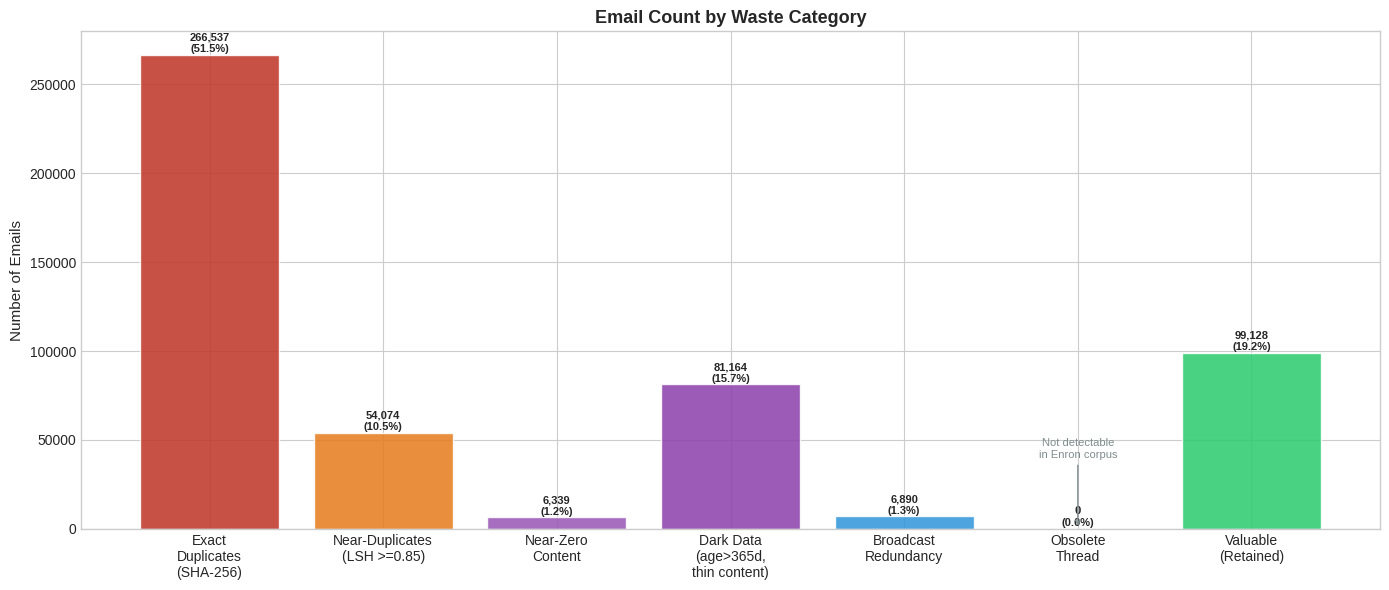

Plot 2a saved: plot2a_waste_category_bar.png


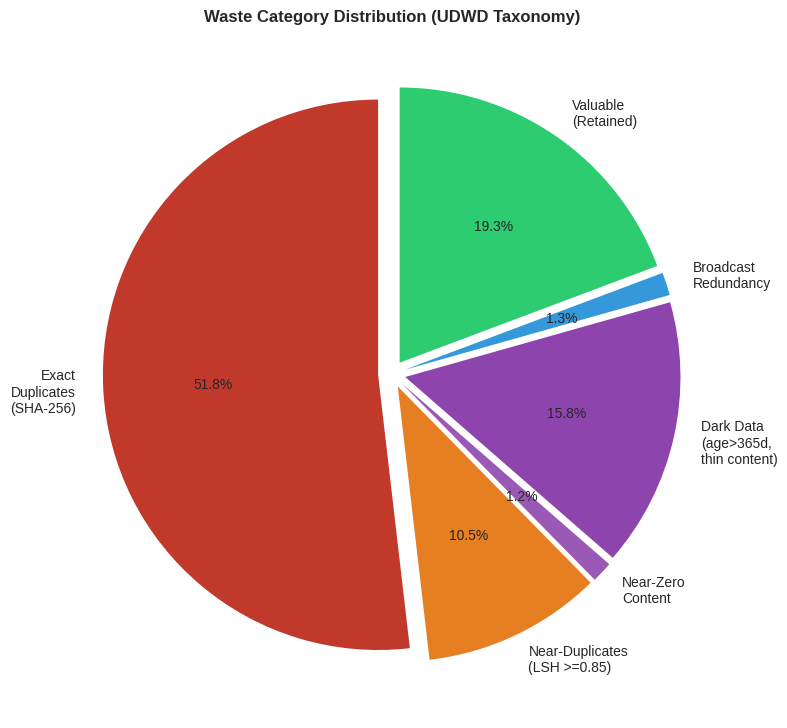

Plot 2b saved: plot2b_waste_category_pie.png


In [ ]:
# ── Plot 2 — Waste Category Distribution ─────────────────────

total_emails = len(df_raw)
cat_counts = {
    'Exact\nDuplicates\n(SHA-256)':        exact_dup_count,
    'Near-Duplicates\n(LSH >=0.85)':        near_dup_count,
    'Near-Zero\nContent':                   (df_clean['waste_category']=='near_zero_content').sum(),
    'Dark Data\n(age>365d,\nthin content)': (df_clean['waste_category']=='dark_data').sum(),
    'Broadcast\nRedundancy':                (df_clean['waste_category']=='broadcast_redundancy').sum(),
    'Obsolete\nThread':                     (df_clean['waste_category']=='obsolete_thread').sum(),
    'Valuable\n(Retained)':                 (df_clean['ground_truth_label']==0).sum()
}
cat_colors = [COLORS['exact_dup'], COLORS['near_dup'],
              '#9B59B6', COLORS['dark_data'], COLORS['neutral'],
              '#95A5A6', COLORS['valuable']]

# ── Plot 2a — Bar chart ───────────────────────────────────────
fig, ax = plt.subplots(figsize=(14, 6))

bars = ax.bar(cat_counts.keys(), cat_counts.values(),
              color=cat_colors, edgecolor='white', alpha=0.88)
ax.set_ylabel('Number of Emails', fontsize=11)
ax.set_title('Email Count by Waste Category', fontsize=13, fontweight='bold')
for bar, val in zip(bars, cat_counts.values()):
    pct = val / total_emails * 100
    ax.text(bar.get_x() + bar.get_width()/2.,
            bar.get_height() + total_emails*0.003,
            f'{val:,}\n({pct:.1f}%)', ha='center', fontsize=8, fontweight='bold')

# Annotation explaining why obsolete thread is zero
ax.annotate('Not detectable\nin Enron corpus',
            xy=(list(cat_counts.keys()).index('Obsolete\nThread'), 0),
            xytext=(list(cat_counts.keys()).index('Obsolete\nThread'), max(cat_counts.values()) * 0.15),
            ha='center', fontsize=8, color='#7F8C8D',
            arrowprops=dict(arrowstyle='->', color='#7F8C8D'))

plt.tight_layout()
plt.savefig('plot2a_waste_category_bar.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot 2a saved: plot2a_waste_category_bar.png')

# ── Plot 2b — Pie chart ───────────────────────────────────────
# Obsolete thread excluded from pie since 0% would clutter the chart
pie_counts = {k: v for k, v in cat_counts.items() if v > 0}
pie_colors = [c for c, v in zip(cat_colors, cat_counts.values()) if v > 0]

fig, ax = plt.subplots(figsize=(8, 8))

ax.pie(list(pie_counts.values()), labels=list(pie_counts.keys()),
       colors=pie_colors, autopct='%1.1f%%', startangle=90,
       explode=[0.05]*len(pie_counts))
ax.set_title('Waste Category Distribution (UDWD Taxonomy)',
             fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('plot2b_waste_category_pie.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot 2b saved: plot2b_waste_category_pie.png')

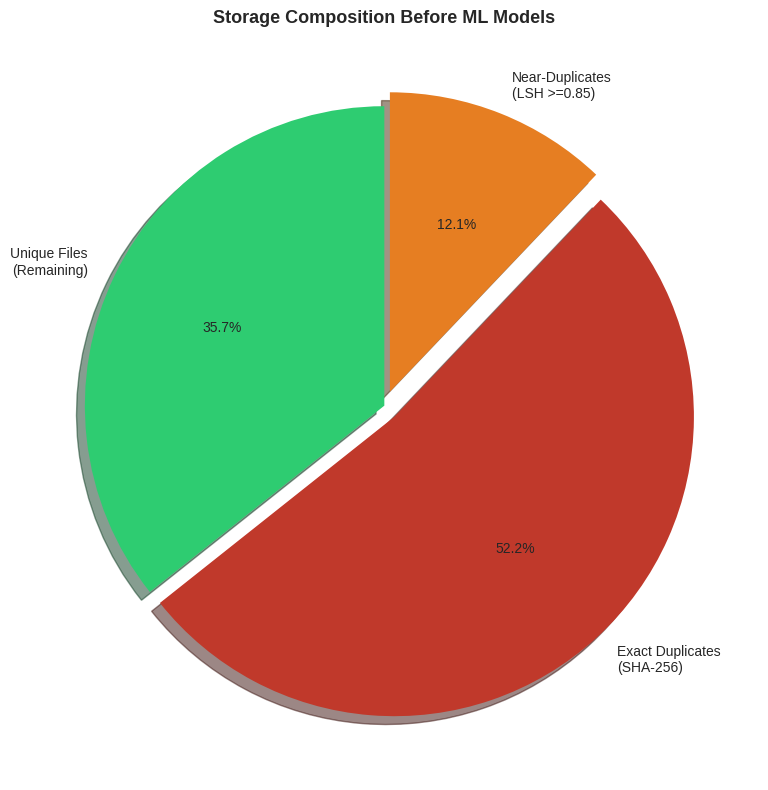

Plot 3a saved: plot3a_storage_composition.png


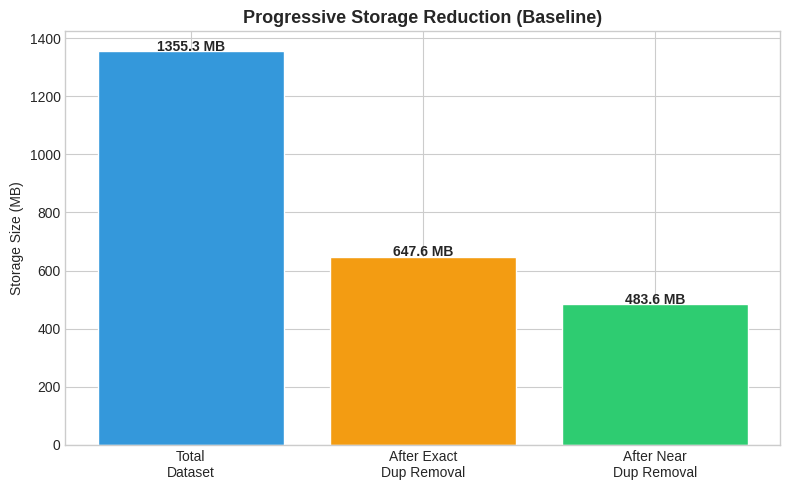

Plot 3b saved: plot3b_storage_reduction.png


In [ ]:
# ── Plot 3 — Baseline Storage Reduction ──────────────────────

total_size_kb = df_raw['file_size_kb'].sum()
exact_pct     = (exact_dup_size_kb / total_size_kb) * 100
near_pct      = (near_dup_size_kb  / total_size_kb) * 100
remaining_pct = 100 - exact_pct - near_pct

# ── Plot 3a — Storage composition pie ────────────────────────
fig, ax = plt.subplots(figsize=(8, 8))

ax.pie([remaining_pct, exact_pct, near_pct],
       labels=['Unique Files\n(Remaining)', 'Exact Duplicates\n(SHA-256)',
               'Near-Duplicates\n(LSH >=0.85)'],
       colors=[COLORS['valuable'], COLORS['exact_dup'], COLORS['near_dup']],
       autopct='%1.1f%%', explode=(0, 0.05, 0.05), shadow=True, startangle=90)
ax.set_title('Storage Composition Before ML Models', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig('plot3a_storage_composition.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot 3a saved: plot3a_storage_composition.png')

# ── Plot 3b — Progressive reduction bar ──────────────────────
bar_sizes = [
    total_size_kb/1024,
    (total_size_kb - exact_dup_size_kb)/1024,
    (total_size_kb - exact_dup_size_kb - near_dup_size_kb)/1024
]

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(['Total\nDataset', 'After Exact\nDup Removal', 'After Near\nDup Removal'],
              bar_sizes,
              color=[COLORS['neutral'], '#F39C12', COLORS['valuable']],
              edgecolor='white')
ax.set_ylabel('Storage Size (MB)')
ax.set_title('Progressive Storage Reduction (Baseline)', fontsize=13, fontweight='bold')
for bar, val in zip(bars, bar_sizes):
    ax.text(bar.get_x()+bar.get_width()/2., bar.get_height()+1,
            f'{val:.1f} MB', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('plot3b_storage_reduction.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot 3b saved: plot3b_storage_reduction.png')

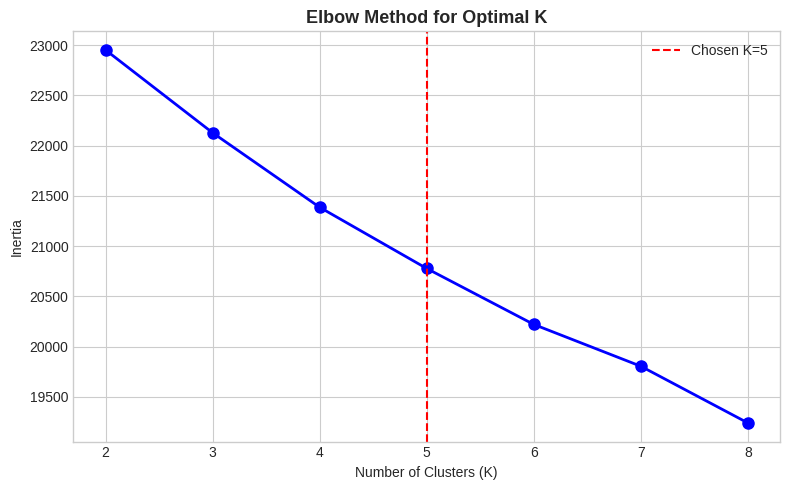

Plot 4a saved: plot4a_kmeans_elbow.png


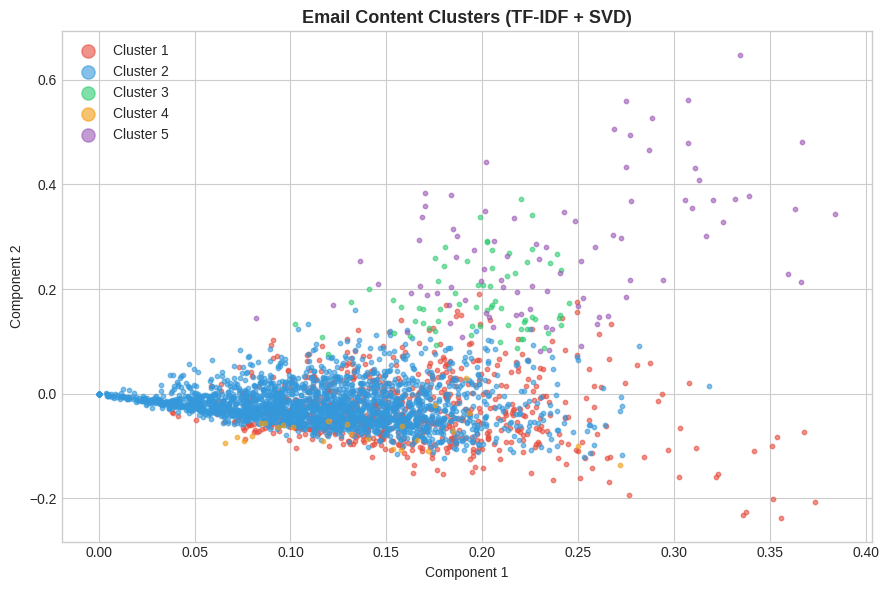

Plot 4b saved: plot4b_kmeans_clusters.png

Content topic distribution per cluster:
   Cluster 1:  43769 emails | 14270 labelled waste (32.6%)
   Cluster 2: 137002 emails | 76257 labelled waste (55.7%)
   Cluster 3:   4289 emails |  2836 labelled waste (66.1%)
   Cluster 4:   1692 emails |   125 labelled waste (7.4%)
   Cluster 5:   6769 emails |   905 labelled waste (13.4%)


In [ ]:
# ── Plot 4 — K-Means Content Clustering ──────────────────────
# K-Means groups emails by content topic similarity (TF-IDF).
# Waste labels are overlaid for observation only — not for prediction.
# High waste concentration in a cluster reflects topic overlap with
# thin or aged content, not a causal relationship.

svd           = TruncatedSVD(n_components=50, random_state=42)
tfidf_reduced = svd.fit_transform(tfidf_features)

inertias = []
K_range  = range(2, 9)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(tfidf_reduced)
    inertias.append(km.inertia_)

optimal_k           = 5
kmeans              = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df_clean['cluster'] = kmeans.fit_predict(tfidf_reduced)

svd_2d = TruncatedSVD(n_components=2, random_state=42)
coords = svd_2d.fit_transform(tfidf_features)

# ── Plot 4a — Elbow method ────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(K_range, inertias, 'bo-', linewidth=2, markersize=8)
ax.axvline(x=optimal_k, color='red', linestyle='--', label=f'Chosen K={optimal_k}')
ax.set_xlabel('Number of Clusters (K)')
ax.set_ylabel('Inertia')
ax.set_title('Elbow Method for Optimal K', fontsize=13, fontweight='bold')
ax.legend()

plt.tight_layout()
plt.savefig('plot4a_kmeans_elbow.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot 4a saved: plot4a_kmeans_elbow.png')

# ── Plot 4b — Content cluster scatter ────────────────────────
c_colors = ['#E74C3C', '#3498DB', '#2ECC71', '#F39C12', '#9B59B6']
s_idx    = np.random.choice(len(coords), min(3000, len(coords)), replace=False)

fig, ax = plt.subplots(figsize=(9, 6))

for c in range(optimal_k):
    mask = df_clean['cluster'].iloc[s_idx] == c
    ax.scatter(coords[s_idx][mask, 0], coords[s_idx][mask, 1],
               c=c_colors[c], label=f'Cluster {c+1}', alpha=0.6, s=10)
ax.set_xlabel('Component 1')
ax.set_ylabel('Component 2')
ax.set_title('Email Content Clusters (TF-IDF + SVD)', fontsize=13, fontweight='bold')
ax.legend(markerscale=3)

plt.tight_layout()
plt.savefig('plot4b_kmeans_clusters.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot 4b saved: plot4b_kmeans_clusters.png')

print()
print('Content topic distribution per cluster:')
for c in range(optimal_k):
    c_df  = df_clean[df_clean['cluster'] == c]
    waste = (c_df['ground_truth_label'] == 1).sum()
    pct   = waste/len(c_df)*100 if len(c_df) > 0 else 0
    print(f'   Cluster {c+1}: {len(c_df):>6} emails | {waste:>5} labelled waste ({pct:.1f}%)')

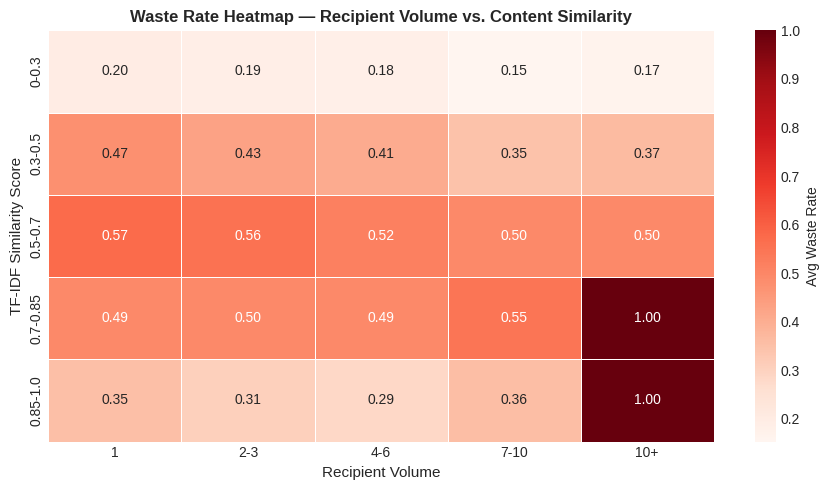

Plot 5a saved: plot5a_recipient_similarity_heatmap.png


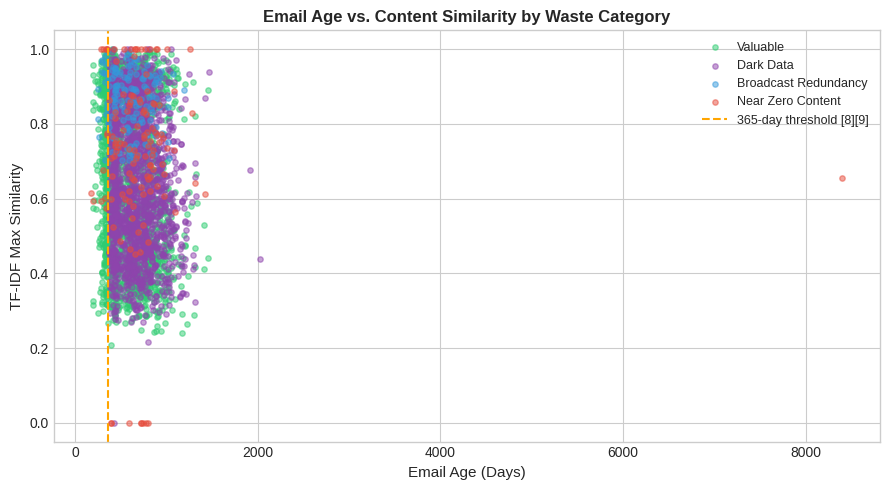

Plot 5b saved: plot5b_age_vs_similarity_scatter.png


In [ ]:
# ── Plot 5 — Recipient Volume vs. Content Similarity ─────────

sample = df_clean[df_clean['tfidf_max_similarity'] > 0].copy()

sample['recip_bin'] = pd.cut(
    sample['recipient_volume'],
    bins=[0, 1, 3, 6, 10, 9999],
    labels=['1', '2-3', '4-6', '7-10', '10+']
)
sample['sim_bin'] = pd.cut(
    sample['tfidf_max_similarity'],
    bins=[0, 0.3, 0.5, 0.7, 0.85, 1.0],
    labels=['0-0.3', '0.3-0.5', '0.5-0.7', '0.7-0.85', '0.85-1.0']
)
heatmap_data = sample.pivot_table(
    values='ground_truth_label', index='sim_bin',
    columns='recip_bin', aggfunc='mean'
)

# ── Plot 5a — Waste rate heatmap ─────────────────────────────
fig, ax = plt.subplots(figsize=(9, 5))

sns.heatmap(heatmap_data, annot=True, fmt='.2f', cmap='Reds',
            linewidths=0.5, ax=ax,
            cbar_kws={'label': 'Avg Waste Rate'})
ax.set_xlabel('Recipient Volume', fontsize=11)
ax.set_ylabel('TF-IDF Similarity Score', fontsize=11)
ax.set_title('Waste Rate Heatmap — Recipient Volume vs. Content Similarity',
             fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('plot5a_recipient_similarity_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot 5a saved: plot5a_recipient_similarity_heatmap.png')

# ── Plot 5b — Email Age vs. Content Similarity scatter ────────
cat_color_map = {
    'valuable':             '#2ECC71',  # green
    'dark_data':            '#8E44AD',  # purple
    'broadcast_redundancy': '#3498DB',  # blue
    'near_zero_content':    '#E74C3C',  # red
}

scatter_s = df_clean.sample(min(4000, len(df_clean)), random_state=42)

fig, ax = plt.subplots(figsize=(9, 5))

for cat, color in cat_color_map.items():
    mask = scatter_s['waste_category'] == cat
    if mask.sum() > 0:
        ax.scatter(
            scatter_s.loc[mask, 'email_age_days'],
            scatter_s.loc[mask, 'tfidf_max_similarity'],
            c=color, label=cat.replace('_', ' ').title(),
            alpha=0.5, s=15
        )
ax.axvline(x=365, color='orange', linestyle='--',
           linewidth=1.5, label='365-day threshold [8][9]')
ax.set_xlabel('Email Age (Days)', fontsize=11)
ax.set_ylabel('TF-IDF Max Similarity', fontsize=11)
ax.set_title('Email Age vs. Content Similarity by Waste Category',
             fontsize=12, fontweight='bold')
ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig('plot5b_age_vs_similarity_scatter.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot 5b saved: plot5b_age_vs_similarity_scatter.png')

## Stage 4 — Machine Learning Models

Two models are trained on the same feature matrix (5,000 TF-IDF dimensions + 4 metadata features: email_age_days, recipient_volume, file_size_kb, content_length). They are evaluated separately — not compared as equivalent classifiers — because they operate under fundamentally different assumptions.

| Model | Type | Contamination / Class weight |
|-------|------|------------------------------|
| Isolation Forest | Unsupervised anomaly detection | contamination = 0.488 (empirical waste ratio) |
| Random Forest | Supervised classification | class_weight = balanced; n_estimators = 100; max_depth = 20 |

**Train / Validation / Test split:** 70% / 15% / 15% stratified (training: 135,459 · validation: 29,033 · test: 29,029)

In [ ]:
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, precision_score, recall_score, confusion_matrix
import joblib

print('=' * 55)
print('STAGE 4 — MODEL DEVELOPMENT')
print('=' * 55)

print()
print('Building leakage-free feature matrix...')
print('   Excluded: is_dark_data, is_stub, is_broadcast (label flags)')
print('   Excluded: has_reply, thread_engagement_freq (constant in corpus)')
print('   Excluded: tfidf_max_similarity, word_count (label conditions)')

metadata_features = df_clean[[
    'email_age_days',    # RQ2 — primary dark data age indicator
    'recipient_volume',  # RQ2 — broadcast redundancy indicator
    'file_size_kb',      # storage footprint
    'content_length',    # character count
]].fillna(0).values

scaler          = StandardScaler()
metadata_scaled = scaler.fit_transform(metadata_features)
X_combined      = sp_hstack([tfidf_features, csr_matrix(metadata_scaled)])

y_true = df_clean['ground_truth_label'].values

print(f'Feature matrix: {X_combined.shape[0]:,} x {X_combined.shape[1]:,} features')
print(f'   TF-IDF: {tfidf_features.shape[1]:,} | Metadata: {metadata_scaled.shape[1]}')
print(f'   Waste:    {y_true.sum():,} ({y_true.mean()*100:.1f}%)')
print(f'   Valuable: {(y_true==0).sum():,} ({(1-y_true.mean())*100:.1f}%)')

STAGE 4 — MODEL DEVELOPMENT

Building leakage-free feature matrix...
   Excluded: is_dark_data, is_stub, is_broadcast (label flags)
   Excluded: has_reply, thread_engagement_freq (constant in corpus)
   Excluded: tfidf_max_similarity, word_count (label conditions)
Feature matrix: 193,521 x 5,004 features
   TF-IDF: 5,000 | Metadata: 4
   Waste:    94,393 (48.8%)
   Valuable: 99,128 (51.2%)


In [ ]:
# ── Train / Validation / Test Split — 70% / 15% / 15% ────────
# Stratified split per thesis [27][7]

print()
print('Splitting 70% Train / 15% Val / 15% Test...')

X_tv, X_test, y_tv, y_test = train_test_split(
    X_combined, y_true, test_size=0.15, random_state=42, stratify=y_true
)
X_train, X_val, y_train, y_val = train_test_split(
    X_tv, y_tv, test_size=0.1765, random_state=42, stratify=y_tv
)

print(f'Train:        {X_train.shape[0]:,} (70%)')
print(f'   Validation:  {X_val.shape[0]:,} (15%)')
print(f'   Test:        {X_test.shape[0]:,} (15%)')


Splitting 70% Train / 15% Val / 15% Test...
Train:        135,459 (70%)
   Validation:  29,033 (15%)
   Test:        29,029 (15%)


In [ ]:
# ── Isolation Forest — Unsupervised Anomaly Detection ─────────

print()
print('Training Isolation Forest (Unsupervised)...')

waste_ratio      = float((y_true == 1).sum() / len(y_true))
if_contamination = min(waste_ratio, 0.5)

print(f'   Actual waste rate:  {waste_ratio:.3f} ({waste_ratio*100:.1f}%)')
print(f'   IF contamination:   {if_contamination:.3f} (capped at 0.5 — sklearn constraint)')

iso_forest = IsolationForest(
    n_estimators  = 100,
    contamination = if_contamination,
    random_state  = 42,
    n_jobs        = -1
)
iso_forest.fit(X_train)

iso_pred               = (iso_forest.predict(X_test) == -1).astype(int)
iso_cm                 = confusion_matrix(y_test, iso_pred)
iso_TN, iso_FP, iso_FN, iso_TP = iso_cm.ravel()
iso_prec = iso_TP/(iso_TP+iso_FP) if (iso_TP+iso_FP) > 0 else 0
iso_rec  = iso_TP/(iso_TP+iso_FN) if (iso_TP+iso_FN) > 0 else 0
iso_f1   = 2*iso_prec*iso_rec/(iso_prec+iso_rec) if (iso_prec+iso_rec) > 0 else 0
iso_acc  = (iso_TP + iso_TN) / (iso_TP + iso_TN + iso_FP + iso_FN)

print(f'   Anomalies detected: {iso_pred.sum():,}')
print(f'   Precision: {iso_prec:.4f}  Recall: {iso_rec:.4f}  F1: {iso_f1:.4f}')

joblib.dump(iso_forest, 'isolation_forest_model.pkl')
print('   Saved: isolation_forest_model.pkl')


Training Isolation Forest (Unsupervised)...
   Actual waste rate:  0.488 (48.8%)
   IF contamination:   0.488 (capped at 0.5 — sklearn constraint)
   Anomalies detected: 14,156
   Precision: 0.2214  Recall: 0.2213  F1: 0.2214
   Saved: isolation_forest_model.pkl


In [ ]:
# ── Random Forest — Supervised Classification ─────────────────

print()
print('Training Random Forest Classifier (Supervised)...')

rf_classifier = RandomForestClassifier(
    n_estimators     = 100,
    class_weight     = 'balanced',
    random_state     = 42,
    n_jobs           = -1,
    max_depth        = 20,
    min_samples_leaf = 5
)
rf_classifier.fit(X_train, y_train)

y_val_pred = rf_classifier.predict(X_val)
print(f'Validation Results:')
print(f'   Precision: {precision_score(y_val, y_val_pred):.4f}')
print(f'   Recall:    {recall_score(y_val, y_val_pred):.4f}')
print(f'   F1-Score:  {f1_score(y_val, y_val_pred):.4f}')

joblib.dump(rf_classifier, 'random_forest_model.pkl')
print('   Saved: random_forest_model.pkl')

print()
print('=' * 55)
print('STAGE 4 COMPLETE')
print('=' * 55)


Training Random Forest Classifier (Supervised)...
Validation Results:
   Precision: 0.9082
   Recall:    0.9184
   F1-Score:  0.9132
   Saved: random_forest_model.pkl

STAGE 4 COMPLETE


## Stage 5 — Evaluation and Validation

Test set performance is reported on the fully held-out 29,029-record partition. Cross-validation is performed on the **training set only** (135,459 records) — the test set is excluded from all CV folds.

In [ ]:
from sklearn.model_selection import StratifiedKFold

print('=' * 55)
print('STAGE 5 — EVALUATION AND VALIDATION')
print('=' * 55)

# ── Random Forest — Test Set Evaluation ───────────────────────
print()
print('Evaluating Random Forest on held-out test set...')

y_test_pred    = rf_classifier.predict(X_test)
cm             = confusion_matrix(y_test, y_test_pred)
TN, FP, FN, TP = cm.ravel()

precision = TP/(TP+FP)
recall    = TP/(TP+FN)
f1        = 2*(precision*recall)/(precision+recall)
accuracy  = (TP+TN)/(TP+TN+FP+FN)

print()
print('── RANDOM FOREST — TEST SET RESULTS ───────────')
print(f'  TP: {TP:,}  TN: {TN:,}  FP: {FP:,}  FN: {FN:,}')
print(f'  Precision: {precision:.4f}')
print(f'  Recall:    {recall:.4f}')
print(f'  F1-Score:  {f1:.4f}')
print(f'  Accuracy:  {accuracy:.4f}')
print('───────────────────────────────────────────────')

STAGE 5 — EVALUATION AND VALIDATION

Evaluating Random Forest on held-out test set...

── RANDOM FOREST — TEST SET RESULTS ───────────
  TP: 12,968  TN: 13,566  FP: 1,304  FN: 1,191
  Precision: 0.9086
  Recall:    0.9159
  F1-Score:  0.9122
  Accuracy:  0.9141
───────────────────────────────────────────────


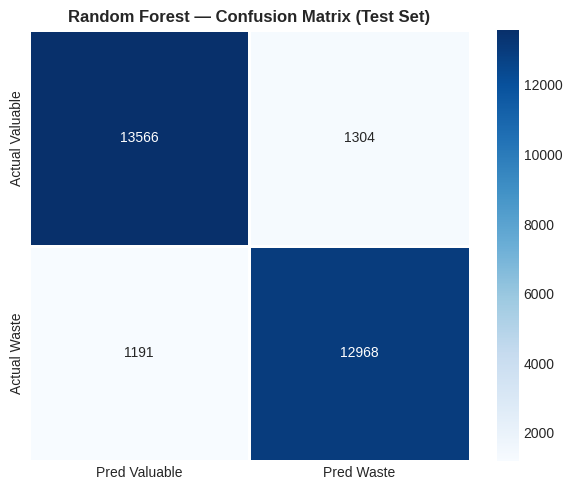

Plot 6A saved: plot6a_rf_confusion_matrix.png


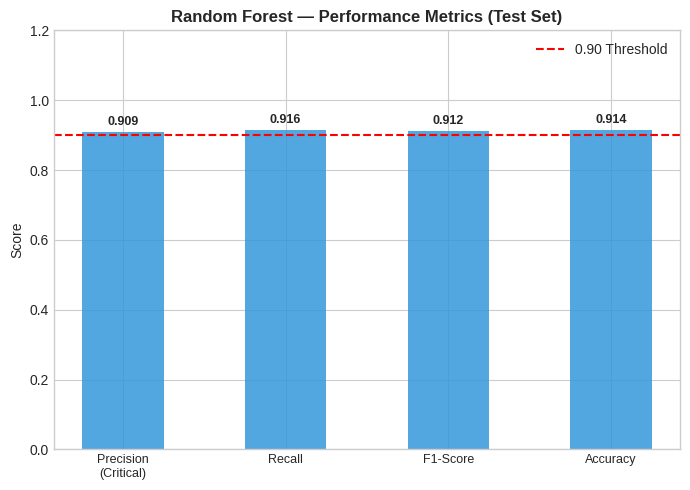

Plot 6B saved: plot6b_rf_metrics.png


In [ ]:
# ── Plot 6A — Random Forest Confusion Matrix ──────────────────

fig, ax = plt.subplots(figsize=(6, 5))

sns.heatmap([[TN, FP], [FN, TP]],
            annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=['Pred Valuable', 'Pred Waste'],
            yticklabels=['Actual Valuable', 'Actual Waste'],
            linewidths=2)
ax.set_title('Random Forest — Confusion Matrix (Test Set)',
             fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('plot6a_rf_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot 6A saved: plot6a_rf_confusion_matrix.png')

# ── Plot 6B — Random Forest Metrics Bar ───────────────────────

m_names = ['Precision\n(Critical)', 'Recall', 'F1-Score', 'Accuracy']
rf_vals = [precision, recall, f1, accuracy]
x       = np.arange(len(m_names))

fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(x, rf_vals, color='#3498DB', alpha=0.85, width=0.5)
ax.axhline(0.90, color='red', linestyle='--', linewidth=1.5, label='0.90 Threshold')
ax.set_ylim(0, 1.2)
ax.set_xticks(x)
ax.set_xticklabels(m_names, fontsize=9)
ax.set_ylabel('Score')
ax.set_title('Random Forest — Performance Metrics (Test Set)',
             fontsize=12, fontweight='bold')
ax.legend()

for i, rv in enumerate(rf_vals):
    ax.text(i, rv + 0.02, f'{rv:.3f}', ha='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig('plot6b_rf_metrics.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot 6B saved: plot6b_rf_metrics.png')

In [ ]:
# ── Isolation Forest — Test Set Results ───────────────────────
print()
print('── ISOLATION FOREST — TEST SET RESULTS ────────')
print(f'  TP: {iso_TP:,}  TN: {iso_TN:,}  FP: {iso_FP:,}  FN: {iso_FN:,}')
print(f'  Precision: {iso_prec:.4f}')
print(f'  Recall:    {iso_rec:.4f}')
print(f'  F1-Score:  {iso_f1:.4f}')
print(f'  Accuracy:  {iso_acc:.4f}')
print('   IF operates without taxonomy labels; detects anomalies in feature space.')
print('───────────────────────────────────────────────')


── ISOLATION FOREST — TEST SET RESULTS ────────
  TP: 3,134  TN: 3,848  FP: 11,022  FN: 11,025
  Precision: 0.2214
  Recall:    0.2213
  F1-Score:  0.2214
  Accuracy:  0.2405
   IF operates without taxonomy labels; detects anomalies in feature space.
───────────────────────────────────────────────


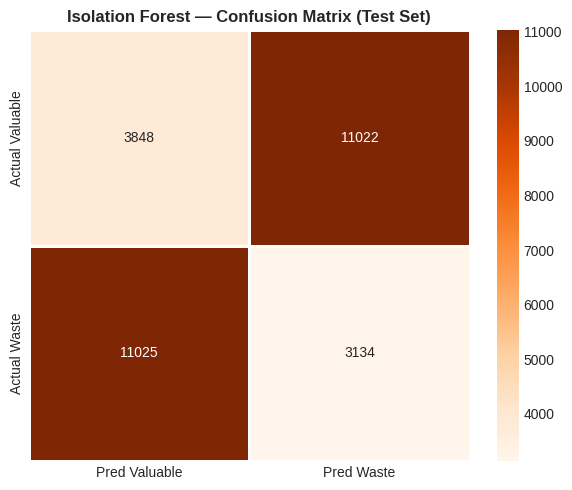

Plot 6C saved: plot6c_if_confusion_matrix.png


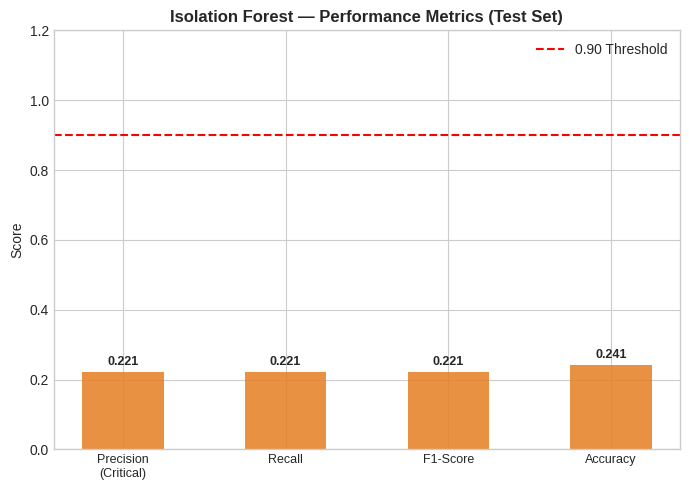

Plot 6D saved: plot6d_if_metrics.png


In [ ]:
# ── Plot 6C — Isolation Forest Confusion Matrix ───────────────

fig, ax = plt.subplots(figsize=(6, 5))

sns.heatmap([[iso_TN, iso_FP], [iso_FN, iso_TP]],
            annot=True, fmt='d', cmap='Oranges', ax=ax,
            xticklabels=['Pred Valuable', 'Pred Waste'],
            yticklabels=['Actual Valuable', 'Actual Waste'],
            linewidths=2)
ax.set_title('Isolation Forest — Confusion Matrix (Test Set)',
             fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('plot6c_if_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot 6C saved: plot6c_if_confusion_matrix.png')

# ── Plot 6D — Isolation Forest Metrics Bar ────────────────────

if_vals = [iso_prec, iso_rec, iso_f1, iso_acc]

fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(x, if_vals, color='#E67E22', alpha=0.85, width=0.5)
ax.axhline(0.90, color='red', linestyle='--', linewidth=1.5, label='0.90 Threshold')
ax.set_ylim(0, 1.2)
ax.set_xticks(x)
ax.set_xticklabels(m_names, fontsize=9)
ax.set_ylabel('Score')
ax.set_title('Isolation Forest — Performance Metrics (Test Set)',
             fontsize=12, fontweight='bold')
ax.legend()

for i, iv in enumerate(if_vals):
    ax.text(i, iv + 0.02, f'{iv:.3f}', ha='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig('plot6d_if_metrics.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot 6D saved: plot6d_if_metrics.png')

In [ ]:
# ── 10-Fold Cross-Validation — Training Set Only ──────────────
# CV operates on X_train only — test set excluded from this procedure.

print()
print('=' * 55)
print('10-FOLD CROSS-VALIDATION (Training Set Only)')
print('=' * 55)
print()

skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
cv_f1, cv_prec, cv_rec = [], [], []

for fold, (tr_idx, te_idx) in enumerate(skf.split(X_train, y_train), 1):
    rf_cv = RandomForestClassifier(
        n_estimators=100, class_weight='balanced',
        random_state=42, n_jobs=-1
    )
    rf_cv.fit(X_train[tr_idx], y_train[tr_idx])
    y_cv_pred = rf_cv.predict(X_train[te_idx])

    cv_f1.append(f1_score(y_train[te_idx], y_cv_pred))
    cv_prec.append(precision_score(y_train[te_idx], y_cv_pred))
    cv_rec.append(recall_score(y_train[te_idx], y_cv_pred))
    print(f'  Fold {fold:>2}: F1={cv_f1[-1]:.4f} | Prec={cv_prec[-1]:.4f} | Rec={cv_rec[-1]:.4f}')

validated_f1   = np.mean(cv_f1)
std_f1         = np.std(cv_f1)
validated_prec = np.mean(cv_prec)
validated_rec  = np.mean(cv_rec)

print()
print('── 10-FOLD CV RESULTS (Training Set) ──────────')
print(f'  Validated F1-Score:  {validated_f1:.4f} +/- {std_f1:.4f}')
print(f'  Validated Precision: {validated_prec:.4f}')
print(f'  Validated Recall:    {validated_rec:.4f}')
print('───────────────────────────────────────────────')


10-FOLD CROSS-VALIDATION (Training Set Only)

  Fold  1: F1=0.9474 | Prec=0.9799 | Rec=0.9169
  Fold  2: F1=0.9518 | Prec=0.9784 | Rec=0.9266
  Fold  3: F1=0.9508 | Prec=0.9784 | Rec=0.9246
  Fold  4: F1=0.9488 | Prec=0.9792 | Rec=0.9202
  Fold  5: F1=0.9507 | Prec=0.9829 | Rec=0.9205
  Fold  6: F1=0.9526 | Prec=0.9814 | Rec=0.9255
  Fold  7: F1=0.9516 | Prec=0.9803 | Rec=0.9245
  Fold  8: F1=0.9518 | Prec=0.9809 | Rec=0.9243
  Fold  9: F1=0.9521 | Prec=0.9826 | Rec=0.9234
  Fold 10: F1=0.9525 | Prec=0.9786 | Rec=0.9278

── 10-FOLD CV RESULTS (Training Set) ──────────
  Validated F1-Score:  0.9510 +/- 0.0016
  Validated Precision: 0.9803
  Validated Recall:    0.9234
───────────────────────────────────────────────


## Stage 6 — SHAP Feature Importance Analysis

SHAP (SHapley Additive exPlanations) values are computed on a **stratified random sample of 1,000 records** from the test set to answer RQ2: which email attributes are the most influential predictors of digital waste?

Two outputs are produced:
- **Plot 8A:** Top-20 features by mean |SHAP| value (all feature types)
- **Plot 8B:** Metadata features only (email_age_days, recipient_volume, file_size_kb, content_length) — isolated to show the contribution of non-TF-IDF signals

In [ ]:
import shap
import matplotlib.patches as mpatches

print()
print('=' * 55)
print('SHAP FEATURE IMPORTANCE ANALYSIS')
print('=' * 55)
print('   Method: SHAP (SHapley Additive exPlanations) on trained Random Forest.')
print('   Sample: 1,000 stratified records from X_test (held-out set).')
print()

X_test_dense = X_test.toarray()

np.random.seed(42)
waste_idx    = np.where(y_test == 1)[0]
valuable_idx = np.where(y_test == 0)[0]

n_waste    = 487
n_valuable = 513

sampled_waste    = np.random.choice(waste_idx,    size=n_waste,    replace=False)
sampled_valuable = np.random.choice(valuable_idx, size=n_valuable, replace=False)
sample_idx       = np.concatenate([sampled_waste, sampled_valuable])
np.random.shuffle(sample_idx)

X_sample = X_test_dense[sample_idx]
y_sample = y_test[sample_idx]

print(f'Sample size:     {len(sample_idx):,} records')
print(f'   Waste:          {(y_sample==1).sum()} ({(y_sample==1).mean()*100:.1f}%)')
print(f'   Valuable:       {(y_sample==0).sum()} ({(y_sample==0).mean()*100:.1f}%)')

metadata_names    = ['email_age_days', 'recipient_volume', 'file_size_kb', 'content_length']
tfidf_names       = [f'tfidf_{w}' for w in tfidf_clean.get_feature_names_out()]
all_feature_names = tfidf_names + metadata_names

print()
print('Computing SHAP values — this may take 3-5 minutes...')

explainer   = shap.TreeExplainer(rf_classifier)
shap_values = explainer.shap_values(X_sample)

if isinstance(shap_values, list):
    sv_waste = shap_values[1]
elif isinstance(shap_values, np.ndarray) and shap_values.ndim == 3:
    sv_waste = shap_values[:, :, 1]
else:
    sv_waste = shap_values

print(f'SHAP values computed: {sv_waste.shape}')

mean_abs_shap = np.abs(sv_waste).mean(axis=0)
ranked_idx    = np.argsort(mean_abs_shap)[::-1]


SHAP FEATURE IMPORTANCE ANALYSIS
   Method: SHAP (SHapley Additive exPlanations) on trained Random Forest.
   Sample: 1,000 stratified records from X_test (held-out set).

Sample size:     1,000 records
   Waste:          487 (48.7%)
   Valuable:       513 (51.3%)

Computing SHAP values — this may take 3-5 minutes...
SHAP values computed: (1000, 5004)



Generating SHAP Feature Importance chart (Top 20)...


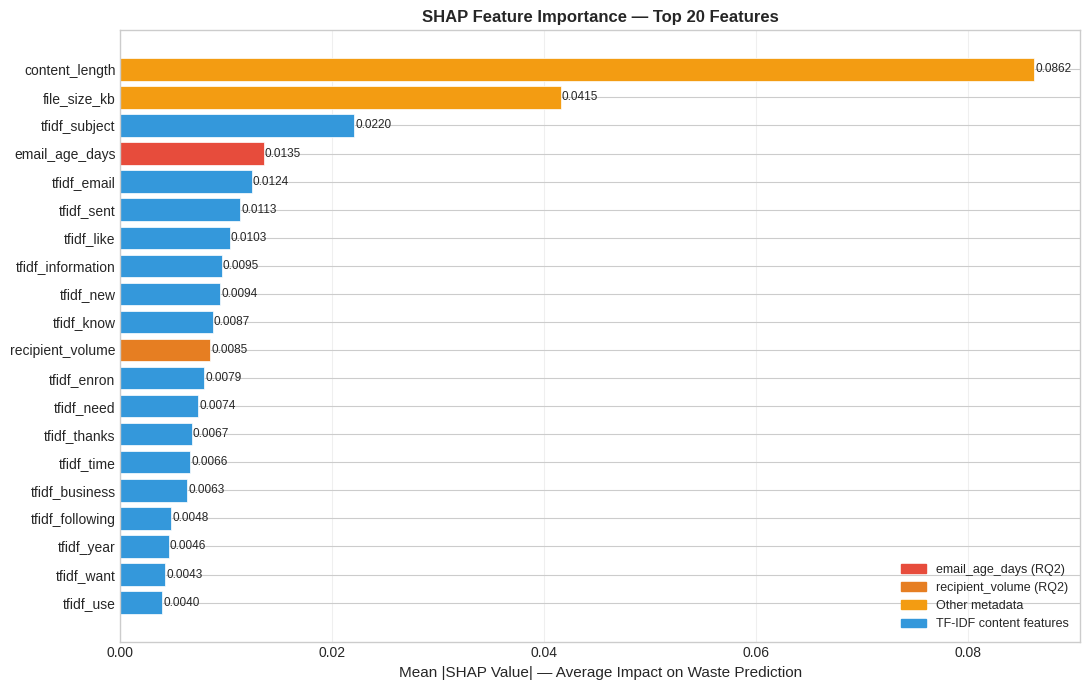

Plot 8A saved: plot8a_shap_top20.png


In [ ]:
# ── Plot 8A — SHAP Top 20 Feature Importance ─────────────────

print()
print('Generating SHAP Feature Importance chart (Top 20)...')

top20_idx   = ranked_idx[:20].tolist()
top20_names = [all_feature_names[i] for i in top20_idx]
top20_vals  = mean_abs_shap[top20_idx]

colors = []
for name in top20_names:
    if name == 'email_age_days':
        colors.append('#E74C3C')
    elif name == 'recipient_volume':
        colors.append('#E67E22')
    elif name in metadata_names:
        colors.append('#F39C12')
    else:
        colors.append('#3498DB')

fig, ax = plt.subplots(figsize=(11, 7))

ax.barh(range(len(top20_names)), top20_vals[::-1],
        color=colors[::-1], edgecolor='white', linewidth=0.5)
ax.set_yticks(range(len(top20_names)))
ax.set_yticklabels(top20_names[::-1], fontsize=10)
ax.set_xlabel('Mean |SHAP Value| — Average Impact on Waste Prediction', fontsize=11)
ax.set_title('SHAP Feature Importance — Top 20 Features',
             fontsize=12, fontweight='bold')

for i, val in enumerate(top20_vals[::-1]):
    ax.text(val + 0.0001, i, f'{val:.4f}', va='center', fontsize=8.5)

legend_patches = [
    mpatches.Patch(color='#E74C3C', label='email_age_days (RQ2)'),
    mpatches.Patch(color='#E67E22', label='recipient_volume (RQ2)'),
    mpatches.Patch(color='#F39C12', label='Other metadata'),
    mpatches.Patch(color='#3498DB', label='TF-IDF content features'),
]
ax.legend(handles=legend_patches, loc='lower right', fontsize=9)
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig('plot8a_shap_top20.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot 8A saved: plot8a_shap_top20.png')

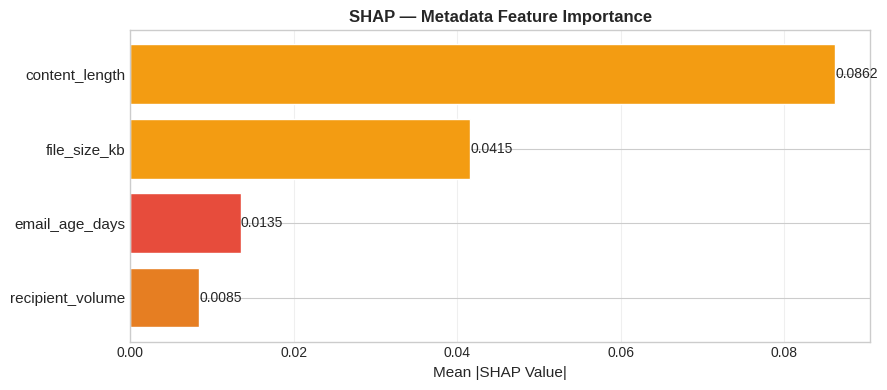

Plot 8B saved: plot8b_shap_metadata_rq2.png

── SHAP ANALYSIS — RQ2 FINDINGS ────────────────────────
   Sample: 1,000 stratified records from X_test

   ALL FEATURES — Top 10 by mean |SHAP|:
    1. [METADATA] content_length                      SHAP = 0.0862
    2. [METADATA] file_size_kb                        SHAP = 0.0415
    3. [TF-IDF  ] tfidf_subject                       SHAP = 0.0220
    4. [METADATA] email_age_days                      SHAP = 0.0135
    5. [TF-IDF  ] tfidf_email                         SHAP = 0.0124
    6. [TF-IDF  ] tfidf_sent                          SHAP = 0.0113
    7. [TF-IDF  ] tfidf_like                          SHAP = 0.0103
    8. [TF-IDF  ] tfidf_information                   SHAP = 0.0095
    9. [TF-IDF  ] tfidf_new                           SHAP = 0.0094
   10. [TF-IDF  ] tfidf_know                          SHAP = 0.0087

   METADATA FEATURES — Ranked by importance:
   1. content_length                 SHAP = 0.0862  |  Overall rank #1
   2. file_

In [ ]:
# ── Plot 8B — SHAP Metadata Features (RQ2) ───────────────────

meta_start  = len(tfidf_names)
meta_shap   = mean_abs_shap[meta_start:]
meta_ranked = np.argsort(meta_shap)[::-1].tolist()

meta_colors        = ['#E74C3C', '#E67E22', '#F39C12', '#F39C12']
meta_colors_ranked = [meta_colors[i] for i in meta_ranked]

fig, ax = plt.subplots(figsize=(9, 4))

ax.barh(range(len(metadata_names)),
        meta_shap[meta_ranked][::-1],
        color=meta_colors_ranked[::-1],
        edgecolor='white')
ax.set_yticks(range(len(metadata_names)))
ax.set_yticklabels([metadata_names[i] for i in meta_ranked][::-1], fontsize=11)
ax.set_xlabel('Mean |SHAP Value|', fontsize=11)
ax.set_title('SHAP — Metadata Feature Importance',
             fontsize=12, fontweight='bold')

for i, val in enumerate(meta_shap[meta_ranked][::-1]):
    ax.text(val + 0.00005, i, f'{val:.4f}', va='center', fontsize=10)

ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('plot8b_shap_metadata_rq2.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot 8B saved: plot8b_shap_metadata_rq2.png')

# ── RQ2 Findings Summary ──────────────────────────────────────
print()
print('── SHAP ANALYSIS — RQ2 FINDINGS ────────────────────────')
print(f'   Sample: {len(sample_idx):,} stratified records from X_test')
print()
print('   ALL FEATURES — Top 10 by mean |SHAP|:')
for rank, idx in enumerate(ranked_idx[:10], 1):
    fname = all_feature_names[idx]
    ftype = 'METADATA' if fname in metadata_names else 'TF-IDF'
    print(f'   {rank:>2}. [{ftype:<8}] {fname:<35} SHAP = {mean_abs_shap[idx]:.4f}')

print()
print('   METADATA FEATURES — Ranked by importance:')
for rank, i in enumerate(meta_ranked, 1):
    mname        = metadata_names[i]
    mshap        = meta_shap[i]
    overall_rank = np.where(ranked_idx == (meta_start + i))[0][0] + 1
    print(f'   {rank}. {mname:<30} SHAP = {mshap:.4f}  |  Overall rank #{overall_rank}')
print('─────────────────────────────────────────────────────────')

## Stage 7 — Environmental Impact Estimation

Storage reduction is translated into energy and carbon estimates using the formula:

> **Energy savings = waste_storage_MB × 0.000002 kWh/MB/year**
> **CO₂ reduction = energy_savings × 0.233 kg CO₂/kWh**

These coefficients represent the annualized energy cost of retaining one megabyte of email data in enterprise storage infrastructure [21][22]. Results are presented as proportional indicators at research scale; the primary contribution metric is the **74.78% storage reduction rate**.

In [ ]:
print()
print('Computing Energy Savings Estimate...')
print('   Formula: 0.000002 kWh/MB/year x 0.233 kg CO2/kWh  [21][28][20]')

total_waste_kb = (
    exact_duplicates['file_size_kb'].sum() +
    near_duplicates['file_size_kb'].sum()  +
    df_clean[df_clean['ground_truth_label']==1]['file_size_kb'].sum()
)

total_size_kb   = df_raw['file_size_kb'].sum()
total_waste_mb  = total_waste_kb / 1024
total_waste_gb  = total_waste_mb / 1024
storage_red_pct = (total_waste_kb / total_size_kb) * 100

KWH_PER_MB_YEAR = 0.000002
CO2_KG_PER_KWH  = 0.233

energy_saved_kwh = total_waste_mb * KWH_PER_MB_YEAR
co2_reduced_kg   = energy_saved_kwh * CO2_KG_PER_KWH

# Scale to 1TB enterprise estimate for context
scale_factor      = (1024 * 1024) / total_waste_mb  # how many times bigger 1TB is
energy_scaled_kwh = energy_saved_kwh * scale_factor
co2_scaled_kg     = co2_reduced_kg   * scale_factor

print()
print('── ENVIRONMENTAL IMPACT ESTIMATE ──────────────')
print(f'  Total waste detected:  {total_waste_mb:.2f} MB ({total_waste_gb:.4f} GB)')
print(f'  Storage Reduction %:   {storage_red_pct:.2f}%')
print(f'  Energy saved (est.):   {energy_saved_kwh:.6f} kWh/year')
print(f'  CO2 reduced (est.):    {co2_reduced_kg:.6f} kg CO2/year')
print('───────────────────────────────────────────────')
print(f'  Projected at 1TB enterprise scale:')
print(f'  Energy saved (est.):   {energy_scaled_kwh:.4f} kWh/year')
print(f'  CO2 reduced (est.):    {co2_scaled_kg:.4f} kg CO2/year')


Computing Energy Savings Estimate...
   Formula: 0.000002 kWh/MB/year x 0.233 kg CO2/kWh  [21][28][20]

── ENVIRONMENTAL IMPACT ESTIMATE ──────────────
  Total waste detected:  1013.51 MB (0.9898 GB)
  Storage Reduction %:   74.78%
  Energy saved (est.):   0.002027 kWh/year
  CO2 reduced (est.):    0.000472 kg CO2/year
───────────────────────────────────────────────
  Projected at 1TB enterprise scale:
  Energy saved (est.):   2.0972 kWh/year
  CO2 reduced (est.):    0.4886 kg CO2/year


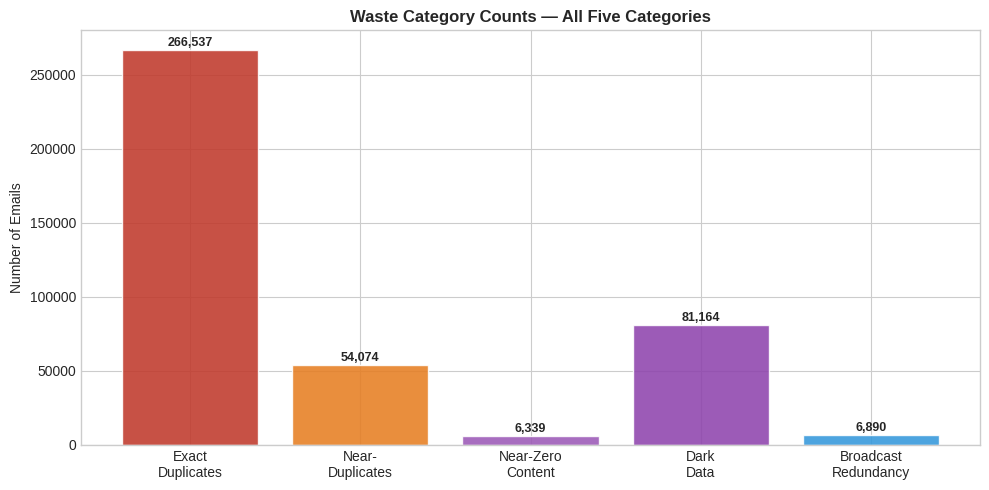

Plot 9A saved: plot9a_waste_counts.png


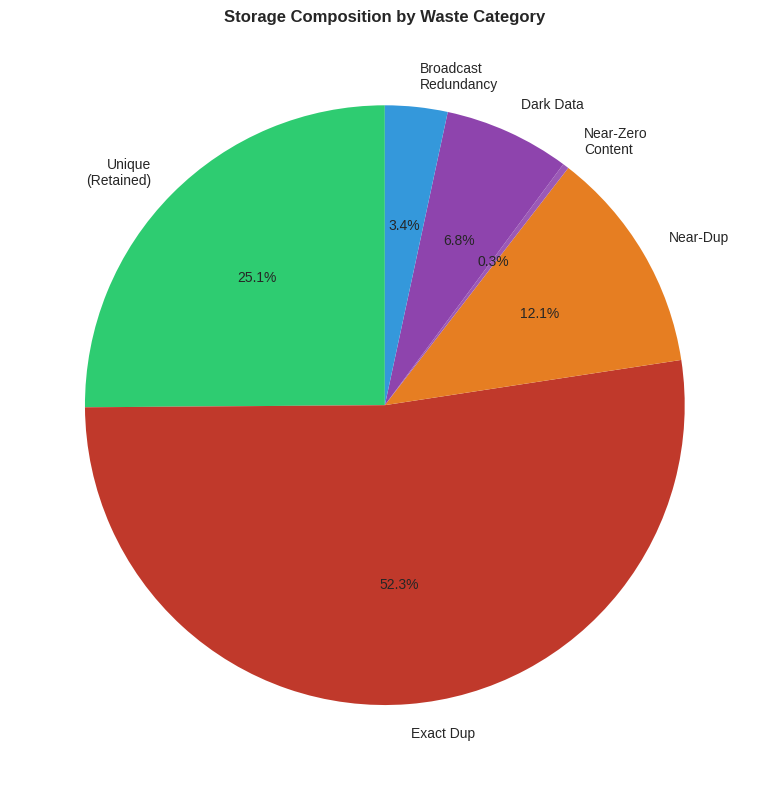

Plot 9B saved: plot9b_storage_composition_by_category.png


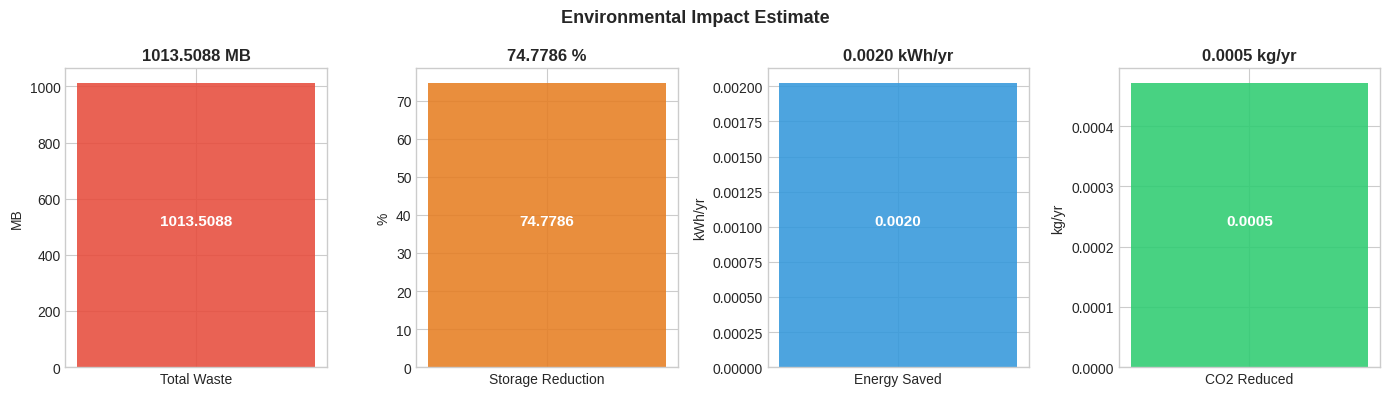

Plot 9C saved: plot9c_environmental_metrics.png


In [ ]:
# ── Plot 9A — Waste Category Counts ──────────────────────────

waste_counts_env = {
    'Exact\nDuplicates':     exact_dup_count,
    'Near-\nDuplicates':     near_dup_count,
    'Near-Zero\nContent':    (df_clean['waste_category']=='near_zero_content').sum(),
    'Dark\nData':            (df_clean['waste_category']=='dark_data').sum(),
    'Broadcast\nRedundancy': (df_clean['waste_category']=='broadcast_redundancy').sum(),
}

bar_colors_env = [
    COLORS['exact_dup'], COLORS['near_dup'],
    '#9B59B6', COLORS['dark_data'], COLORS['neutral'],
]

fig, ax = plt.subplots(figsize=(10, 5))

bars   = ax.bar(waste_counts_env.keys(), waste_counts_env.values(),
                color=bar_colors_env, edgecolor='white', alpha=0.88)
max_val = max(waste_counts_env.values())
ax.set_title('Waste Category Counts — All Five Categories', fontsize=12, fontweight='bold')
ax.set_ylabel('Number of Emails')
for bar, val in zip(bars, waste_counts_env.values()):
    ax.text(bar.get_x()+bar.get_width()/2.,
            bar.get_height()+max_val*0.01,
            f'{val:,}', ha='center', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.savefig('plot9a_waste_counts.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot 9A saved: plot9a_waste_counts.png')

# ── Plot 9B — Storage composition pie ────────────────────────
unique_kb    = df_clean[df_clean['ground_truth_label']==0]['file_size_kb'].sum()
dark_kb      = df_clean[df_clean['waste_category']=='dark_data']['file_size_kb'].sum()
stub_kb      = df_clean[df_clean['waste_category']=='near_zero_content']['file_size_kb'].sum()
broadcast_kb = df_clean[df_clean['waste_category']=='broadcast_redundancy']['file_size_kb'].sum()

sizes_pie  = [max(v, 0.001) for v in [unique_kb, exact_dup_size_kb,
                                        near_dup_size_kb, stub_kb,
                                        dark_kb, broadcast_kb]]
labels_pie = ['Unique\n(Retained)', 'Exact Dup', 'Near-Dup',
              'Near-Zero\nContent', 'Dark Data', 'Broadcast\nRedundancy']
colors_pie = [COLORS['valuable'], COLORS['exact_dup'], COLORS['near_dup'],
              '#9B59B6', COLORS['dark_data'], COLORS['neutral']]

fig, ax = plt.subplots(figsize=(8, 8))
ax.pie(sizes_pie, labels=labels_pie, colors=colors_pie,
       autopct='%1.1f%%', startangle=90)
ax.set_title('Storage Composition by Waste Category', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('plot9b_storage_composition_by_category.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot 9B saved: plot9b_storage_composition_by_category.png')

# ── Plot 9C — Environmental metric bars ──────────────────────
env_labels = ['Total Waste\n(MB)', 'Storage\nReduction (%)',
              'Energy Saved\n(kWh/yr)', 'CO2 Reduced\n(kg/yr)']
env_vals   = [total_waste_mb, storage_red_pct, energy_saved_kwh, co2_reduced_kg]
env_colors = ['#E74C3C', '#E67E22', '#3498DB', '#2ECC71']

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
fig.suptitle('Environmental Impact Estimate', fontsize=13, fontweight='bold')

for ax, label, val, unit, color in zip(
    axes,
    ['Total Waste', 'Storage Reduction', 'Energy Saved', 'CO2 Reduced'],
    env_vals,
    ['MB', '%', 'kWh/yr', 'kg/yr'],
    env_colors
):
    ax.bar([label], [val], color=color, alpha=0.88)
    ax.set_ylabel(unit)
    ax.set_title(f'{val:.4f} {unit}', fontweight='bold')
    text_y = val * 0.5 if val > 0 else 0.5
    ax.text(0, text_y, f'{val:.4f}',
            ha='center', color='white', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.savefig('plot9c_environmental_metrics.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot 9C saved: plot9c_environmental_metrics.png')

## Final Results Summary

All key metrics from Chapters 4 and 5 are printed below for verification against the thesis tables. Values here are the ground truth for any discrepancy between the paper and this notebook.

In [ ]:
# ── FINAL RESULTS SUMMARY ─────────────────────────────────────

print()
print('=' * 55)
print('FINAL RESULTS — CHAPTER 4 AND 5')
print('=' * 55)
print()
print('── DATASET ─────────────────────────────────────')
print(f'  Dataset:             Enron Email Corpus (FERC Release)')
print(f'  Total emails:        {len(df_raw):,}')
print(f'  After preprocessing: {len(df_clean):,} records')
print()
print('── STAGE 2 — WASTE TAXONOMY RESULTS ────────────')
print(f'  Exact duplicates (SHA-256):                    {exact_dup_count:,}')
print(f'  Near-duplicates (LSH >= 0.85):                 {near_dup_count:,}')
print(f'  Near-zero content (word_count <= 5):           {(df_clean["waste_category"]=="near_zero_content").sum():,}')
print(f'  Dark data (age > 365d, word_count <= 50):      {(df_clean["waste_category"]=="dark_data").sum():,}')
print(f'  Broadcast redundancy (recip >= 10, sim >= 0.70): {(df_clean["waste_category"]=="broadcast_redundancy").sum():,}')
print(f'  Valuable (retained):                           {(df_clean["ground_truth_label"]==0).sum():,}')
print(f'  Total waste rate (post-dedup):                 {(df_clean["ground_truth_label"]==1).sum()/len(df_clean)*100:.1f}%')
print()
print('── STAGE 3 — EDA ────────────────────────────────')
print(f'  Total dataset size:      {df_raw["file_size_kb"].sum()/1024:.2f} MB')
print(f'  Exact dup storage:       {exact_dup_size_kb/1024:.2f} MB')
print(f'  Near-dup storage:        {near_dup_size_kb/1024:.2f} MB')
print(f'  Baseline reduction:      {exact_pct+near_pct:.2f}%')
print()
print('── STAGE 5 — MODEL RESULTS ──────────────────────')
print('  Random Forest (Supervised):')
print(f'    TP: {TP:,}  TN: {TN:,}  FP: {FP:,}  FN: {FN:,}')
print(f'    Precision (CRITICAL): {precision:.4f}')
print(f'    Recall:               {recall:.4f}')
print(f'    F1-Score:             {f1:.4f}')
print(f'    Accuracy:             {accuracy:.4f}')
print(f'    Validated F1 (10-CV, train only): {validated_f1:.4f} +/- {std_f1:.4f}')
print(f'    Validated Precision:  {validated_prec:.4f}')
print(f'    Validated Recall:     {validated_rec:.4f}')
print()
print('  Isolation Forest (Unsupervised):')
print(f'    TP: {iso_TP:,}  TN: {iso_TN:,}  FP: {iso_FP:,}  FN: {iso_FN:,}')
print(f'    Precision: {iso_prec:.4f}')
print(f'    Recall:    {iso_rec:.4f}')
print(f'    F1-Score:  {iso_f1:.4f}')
print(f'    Accuracy:  {iso_acc:.4f}')
print(f'    Contamination: {min(float((y_true==1).sum()/len(y_true)),0.5):.3f} (capped at 0.5)')
print()
print('── ENVIRONMENTAL ESTIMATE ───────────────────────')
print(f'  Formula: 0.000002 kWh/MB/yr x 0.233 kg CO2/kWh  [21][28][20]')
print(f'  Total waste detected:  {total_waste_mb:.2f} MB ({total_waste_gb:.4f} GB)')
print(f'  Storage Reduction %:   {storage_red_pct:.2f}%')
print(f'  Energy saved (est.):   {energy_saved_kwh:.6f} kWh/year')
print(f'  CO2 reduced (est.):    {co2_reduced_kg:.6f} kg CO2/year')


FINAL RESULTS — CHAPTER 4 AND 5

── DATASET ─────────────────────────────────────
  Dataset:             Enron Email Corpus (FERC Release)
  Total emails:        517,401
  After preprocessing: 193,521 records

── STAGE 2 — WASTE TAXONOMY RESULTS ────────────
  Exact duplicates (SHA-256):                    266,537
  Near-duplicates (LSH >= 0.85):                 54,074
  Near-zero content (word_count <= 5):           6,339
  Dark data (age > 365d, word_count <= 50):      81,164
  Broadcast redundancy (recip >= 10, sim >= 0.70): 6,890
  Valuable (retained):                           99,128
  Total waste rate (post-dedup):                 48.8%

── STAGE 3 — EDA ────────────────────────────────
  Total dataset size:      1355.35 MB
  Exact dup storage:       707.79 MB
  Near-dup storage:        163.93 MB
  Baseline reduction:      64.32%

── STAGE 5 — MODEL RESULTS ──────────────────────
  Random Forest (Supervised):
    TP: 12,968  TN: 13,566  FP: 1,304  FN: 1,191
    Precision (CRITIC